# Estimated Bat Speed — Marshall (2017) Physics Method, Validated Against Measured Bat Speed

Implements the bat-speed estimation from David Marshall's *Reverse Engineering
Swing Mechanics from Statcast Data* (FanGraphs Community, Sept 2017), validates
it against Statcast's **measured** `bat_speed` (available 2024+, which did not
exist when the article was written), and devises a translation to Frontier
League hitters.

**The physics (Alan Nathan's collision model):**

$$EV = e_A \cdot v_{ball} + (1 + e_A) \cdot v_{bat}$$

solved for bat speed:

$$v_{bat} = \frac{EV - e_A \cdot v_{ball}}{1 + e_A}$$

- $v_{ball}$ = pitch speed **at the plate** = release speed × (1 − 0.084)
- $e_A$ = collision efficiency, calibrated **per hitter, linearly in EV**:
  the hitter's top-15-BBE mean EV anchors $e_A = 0.21$ (sweet spot), the
  bottom-15-BBE mean EV anchors $e_A = -0.10$ (worst contact)
- −0.42 mph adjustment for a 34in/32oz bat (Nathan's reference was 34/31)
- Expected league landmarks (2015–17): mean ≈ 71.7 mph, range ≈ 63–83

**Why this is the right base for an FL translation:** the constants are
physics (wood bat + ball collision properties), not MLB population artifacts —
unlike the PAA/PAD calibrations, which were fit to MLB bat-tracking and failed
the KS distribution check for FL transfer. The per-hitter $e_A$ anchors assume
only "this hitter's best contact is sweet-spot contact," which is as true in
Marion, Illinois as in Yankee Stadium. What may NOT transfer is any
*measurement-method* bias correction fit on MLB — §8 tests that explicitly.

**Pipeline**
1. Physics functions
2. MLB estimate per batter-season (2024–2025)
3. Measured bat speed per batter-season (Statcast `bat_speed`)
4. Cross-reference: estimated vs measured (r, bias, calibration, held-out)
5. Reliability of the estimate (split-half)
6. FL estimate (same physics, TrackMan `exit_speed` + `rel_speed`)
7. MLB vs FL distribution comparison (KS + support overlap)
8. Translation: calibrated-physics vs Z-score approaches, honestly compared

## 1. Imports & Config

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.stats import spearmanr, pearsonr, ks_2samp
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from joblib import Parallel, delayed
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", "{:.3f}".format)

# ── Marshall / Nathan physics constants ───────────────────────────────────────
EA_SWEET_SPOT   = 0.21     # collision efficiency at sweet spot (Nathan 2003)
EA_WORST        = -0.10    # collision efficiency for weakest contact
PITCH_DECAY     = 0.084    # pitch loses 8.4% of release speed by the plate
BAT_WEIGHT_ADJ  = -0.42    # 34/32 bat vs Nathan's 34/31 reference (mph)
TOP_N_ANCHOR    = 15       # BBE count for the eA anchors (top-15 / bottom-15)

# ── Qualification ─────────────────────────────────────────────────────────────
MIN_BBE_MLB = 40          # per batter-season (matches the article)
MIN_BBE_FL  = 40        # FL batter-year floor (smaller seasons)

# Sanity landmarks from the article (2015-17): league mean ≈71.7, range 63–83
print("Config OK")

Config OK


## 2. Physics Functions

Per-hitter eA calibration, then per-BBE bat speed via the collision equation.
Numpy-array machinery so the split-half reliability section can reuse it.

In [2]:
def estimate_bat_speed_arrays(ev, rel_speed):
    """
    Marshall's method on raw arrays for ONE batter-season.
    Returns (per-BBE bat speed array, mean eA) or (None, nan) if insufficient data.

    Steps:
      1. Anchor eA linearly in EV: top-15 mean EV -> 0.21, bottom-15 mean EV -> -0.10
      2. v_ball at plate = rel_speed * (1 - 0.084)
      3. v_bat = (EV - eA*v_ball) / (1 + eA), minus 0.42 mph bat-weight adj
    """
    mask = ~np.isnan(ev) & ~np.isnan(rel_speed)
    ev, rel_speed = ev[mask], rel_speed[mask]
    n = len(ev)
    if n < 2 * TOP_N_ANCHOR:          # need distinct top-15 and bottom-15
        return None, np.nan

    k = TOP_N_ANCHOR
    ev_sorted = np.sort(ev)
    ev_top    = ev_sorted[-k:].mean()   # anchors eA = 0.21
    ev_bottom = ev_sorted[:k].mean()    # anchors eA = -0.10

    if ev_top <= ev_bottom:             # degenerate (shouldn't happen)
        return None, np.nan

    # Linear map EV -> eA, clipped to the physical range
    slope_ea = (EA_SWEET_SPOT - EA_WORST) / (ev_top - ev_bottom)
    ea = EA_WORST + slope_ea * (ev - ev_bottom)
    ea = np.clip(ea, EA_WORST, EA_SWEET_SPOT)

    v_ball = rel_speed * (1.0 - PITCH_DECAY)
    v_bat  = (ev - ea * v_ball) / (1.0 + ea) + BAT_WEIGHT_ADJ
    return v_bat, ea.mean()


def batter_season_estimate(ev, rel_speed):
    """Season-level summary for one batter: mean/max estimated bat speed + mean eA."""
    v_bat, ea_mean = estimate_bat_speed_arrays(ev, rel_speed)
    if v_bat is None:
        return np.nan, np.nan, np.nan
    return v_bat.mean(), np.percentile(v_bat, 90), ea_mean

print("Physics functions defined")

Physics functions defined


## 3. MLB — Estimated Bat Speed per Batter-Season

In [3]:
def load_statcast(cache_path):
    p = Path(cache_path)
    if p.exists():
        print(f"Loading {p} …")
        return pd.read_parquet(p)
    raise FileNotFoundError(f"{p} not found — build the cache first.")

raw24 = load_statcast("statcast_2024.parquet"); raw24["season"] = 2024
raw25 = load_statcast("statcast_2025.parquet"); raw25["season"] = 2025
raw = pd.concat([raw24, raw25], ignore_index=True)

mlb_bbe = raw[
    (raw["type"] == "X") &
    raw["launch_speed"].notna() &
    raw["release_speed"].notna() &
    raw["batter"].notna()
].copy()
print(f"MLB BBE rows: {len(mlb_bbe):,}   batters: {mlb_bbe['batter'].nunique():,}")

est_rows = []
for (b, s), g in mlb_bbe.groupby(["batter", "season"]):
    if len(g) < MIN_BBE_MLB:
        continue
    ev  = g["launch_speed"].to_numpy(dtype=np.float64)
    rel = g["release_speed"].to_numpy(dtype=np.float64)
    bs_mean, bs_p90, ea_mean = batter_season_estimate(ev, rel)
    est_rows.append({"batter": b, "season": s, "n_bbe": len(g),
                     "est_bat_speed": bs_mean, "est_bat_speed_p90": bs_p90,
                     "mean_ea": ea_mean})

mlb_est = pd.DataFrame(est_rows).dropna(subset=["est_bat_speed"])
print(f"Qualified batter-seasons (≥{MIN_BBE_MLB} BBE): {len(mlb_est)}")
print(mlb_est[["est_bat_speed", "est_bat_speed_p90", "mean_ea"]].describe().round(2))
print("\nArticle landmarks (2015-17): mean ≈ 71.7 mph, min ≈ 63, max ≈ 83 —"
      "\nif today's numbers run a bit higher, remember league EV has climbed since 2017.")

Loading statcast_2024.parquet …
Loading statcast_2025.parquet …
MLB BBE rows: 252,804   batters: 1,241
Qualified batter-seasons (≥100 BBE): 800
       est_bat_speed  est_bat_speed_p90  mean_ea
count        800.000            800.000  800.000
mean          71.850             74.610    0.100
std            3.160              2.560    0.010
min           61.860             65.220    0.060
25%           69.920             72.980    0.100
50%           72.280             74.560    0.100
75%           73.940             76.240    0.110
max           81.680             85.770    0.140

Article landmarks (2015-17): mean ≈ 71.7 mph, min ≈ 63, max ≈ 83 —
if today's numbers run a bit higher, remember league EV has climbed since 2017.


## 4. MLB — Measured Bat Speed per Batter-Season

Statcast has tracked actual bat speed (at the sweet spot — same reference point
as the Marshall estimate) since 2024. This is the ground truth the article
never had.

In [4]:
swings = raw[raw["bat_speed"].notna()].copy()
print(f"Swings with measured bat_speed: {len(swings):,}")

measured = (swings.groupby(["batter", "season"])
            .agg(measured_bat_speed=("bat_speed", "mean"),
                 measured_bat_speed_p90=("bat_speed", lambda s: s.quantile(0.90)),
                 n_swings=("bat_speed", "size"))
            .reset_index())
measured = measured[measured["n_swings"] >= 100]
print(f"Batter-seasons with ≥100 measured swings: {len(measured)}")
print(measured[["measured_bat_speed", "measured_bat_speed_p90"]].describe().round(2))

# NOTE: measured mean here averages ALL tracked swings (including checked/
# defensive swings, which drag the mean down). The estimate only sees swings
# that produced fair contact. Expect the estimate to run slightly hot vs the
# all-swings measured mean for exactly this reason — the calibration in §5
# absorbs that as an intercept/slope, and the correlation is what validates
# the method.

Swings with measured bat_speed: 647,514
Batter-seasons with ≥100 measured swings: 1037
       measured_bat_speed  measured_bat_speed_p90
count            1037.000                1037.000
mean               69.200                  75.780
std                 2.970                   2.760
min                60.390                  67.300
25%                67.300                  74.000
50%                69.460                  75.850
75%                71.150                  77.620
max                79.610                  84.900


## 5. Cross-Reference — Estimated vs Measured

Batter-seasons with both estimate and measurement: 800

Estimated vs measured bat speed: r = 0.750   ρ = 0.717   mean bias = +2.48 mph

Calibration: measured ≈ 18.98 + 0.701 × estimated
Held-out bias after calibration: +0.03 mph
(slope well below 1 = the estimate overstates spread; near 1 = pure offset)


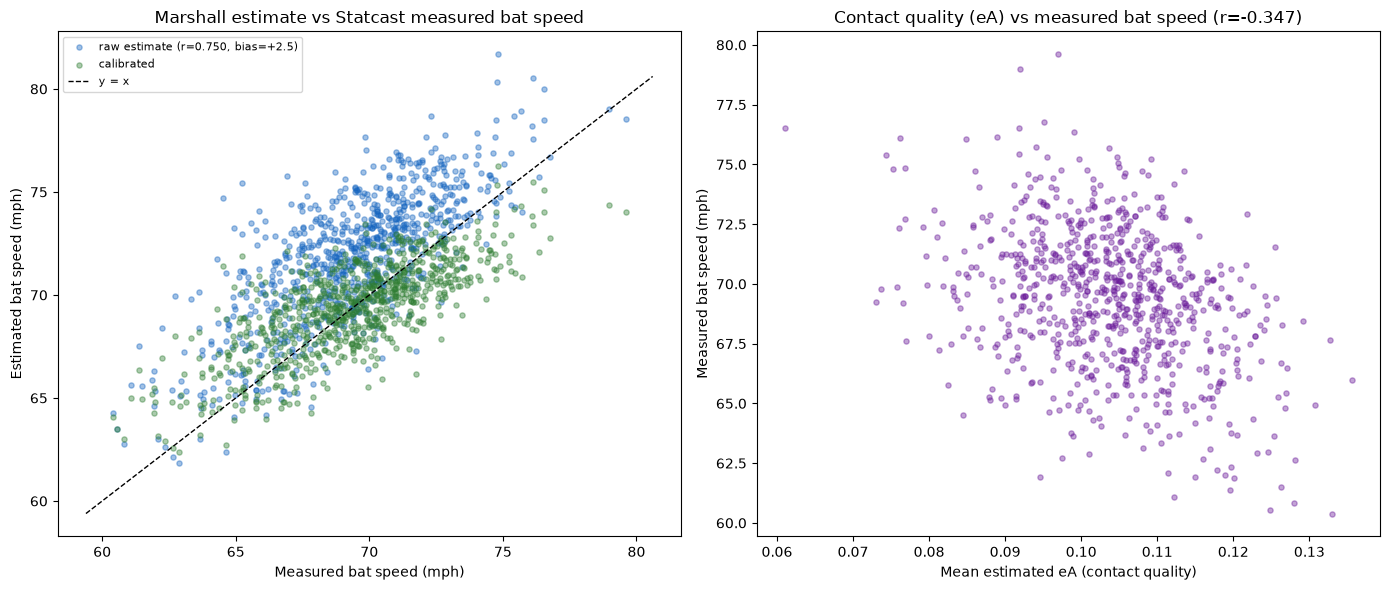

In [5]:
xref = mlb_est.merge(measured, on=["batter", "season"], how="inner").dropna(
    subset=["est_bat_speed", "measured_bat_speed"])
print(f"Batter-seasons with both estimate and measurement: {len(xref)}")

r_est, _ = pearsonr(xref["est_bat_speed"], xref["measured_bat_speed"])
rho_est, _ = spearmanr(xref["est_bat_speed"], xref["measured_bat_speed"])
bias_est = (xref["est_bat_speed"] - xref["measured_bat_speed"]).mean()
print(f"\nEstimated vs measured bat speed: r = {r_est:.3f}   ρ = {rho_est:.3f}   "
      f"mean bias = {bias_est:+.2f} mph")

# Calibration (same protocol as PAA/PAD_lac: fit, then held-out bias check)
tr_idx, te_idx = train_test_split(np.arange(len(xref)), test_size=0.3, random_state=42)
slope_c, intercept_c, r_c, *_ = stats.linregress(
    xref["est_bat_speed"].to_numpy()[tr_idx],
    xref["measured_bat_speed"].to_numpy()[tr_idx])
pred_te = intercept_c + slope_c * xref["est_bat_speed"].to_numpy()[te_idx]
bias_te = (pred_te - xref["measured_bat_speed"].to_numpy()[te_idx]).mean()
print(f"\nCalibration: measured ≈ {intercept_c:.2f} + {slope_c:.3f} × estimated")
print(f"Held-out bias after calibration: {bias_te:+.2f} mph")
print("(slope well below 1 = the estimate overstates spread; near 1 = pure offset)")

xref["est_bat_speed_cal"] = intercept_c + slope_c * xref["est_bat_speed"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ax = axes[0]
ax.scatter(xref["measured_bat_speed"], xref["est_bat_speed"], s=14, alpha=0.4,
           color="#1565C0", label=f"raw estimate (r={r_est:.3f}, bias={bias_est:+.1f})")
ax.scatter(xref["measured_bat_speed"], xref["est_bat_speed_cal"], s=14, alpha=0.4,
           color="#2E7D32", label="calibrated")
lims = [xref["measured_bat_speed"].min() - 1, xref["measured_bat_speed"].max() + 1]
ax.plot(lims, lims, "k--", lw=1, label="y = x")
ax.set_xlabel("Measured bat speed (mph)")
ax.set_ylabel("Estimated bat speed (mph)")
ax.set_title("Marshall estimate vs Statcast measured bat speed")
ax.legend(fontsize=8)

# eA vs squared-up-ness sanity: mean_ea should track measured squared-up ability
ax = axes[1]
ax.scatter(xref["mean_ea"], xref["measured_bat_speed"], s=14, alpha=0.4, color="#6A1B9A")
ax.set_xlabel("Mean estimated eA (contact quality)")
ax.set_ylabel("Measured bat speed (mph)")
r_ea, _ = pearsonr(xref["mean_ea"], xref["measured_bat_speed"])
ax.set_title(f"Contact quality (eA) vs measured bat speed (r={r_ea:.3f})")
plt.tight_layout(); plt.show()

### 5b. Where does the estimate fail? (Rickie Weeks check)

The article's key diagnostic: fast-but-wild swingers (high true bat speed, low
contact quality) should be where an EV-derived estimate diverges most from
measured. Residual vs measured whiff tendency, using swing-level data.

In [6]:
# Residual: how much the (calibrated) estimate misses measured, per batter-season
xref["resid"] = xref["est_bat_speed_cal"] - xref["measured_bat_speed"]

# Squared-up rate per batter-season from Statcast (2024+), the direct measure
# of contact quality — the thing eA is a proxy for
if "squared_up" in raw.columns:
    sq = (raw[raw["bat_speed"].notna()]
          .groupby(["batter", "season"])
          .agg(squared_up_rate=("squared_up", "mean"))
          .reset_index())
    xref2 = xref.merge(sq, on=["batter", "season"], how="left").dropna(subset=["squared_up_rate"])
    r_resid, _ = pearsonr(xref2["squared_up_rate"], xref2["resid"])
    print(f"Residual vs squared-up rate: r = {r_resid:.3f}")
    print("Positive r expected: the estimate runs hot for clean squarers and cold")
    print("for wild swingers (whose true speed EV never fully reveals).")

    fig, ax = plt.subplots(figsize=(7.5, 5.5))
    ax.scatter(xref2["squared_up_rate"], xref2["resid"], s=14, alpha=0.4, color="#E65100")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("Squared-up rate (measured)")
    ax.set_ylabel("Estimate − measured (mph)")
    ax.set_title("Estimate residual vs contact quality")
    plt.tight_layout(); plt.show()
else:
    print("squared_up column not in parquet — skipping (re-pull statcast with it to run this check)")

squared_up column not in parquet — skipping (re-pull statcast with it to run this check)


## 6. Reliability — Split-Half of the Estimate

In [7]:
def build_arrays_mlb(df, min_bbe):
    arrays = {}
    for (b, s), g in df.groupby(["batter", "season"]):
        gc = g.dropna(subset=["launch_speed", "release_speed"])
        if len(gc) < min_bbe * 2:
            continue
        arrays[(b, s)] = (gc["launch_speed"].to_numpy(dtype=np.float64),
                          gc["release_speed"].to_numpy(dtype=np.float64))
    return arrays

def _one_split_bs(arrays, seed):
    rng = np.random.default_rng(seed)
    h1, h2 = [], []
    for (b, s), (ev, rel) in arrays.items():
        idx = rng.permutation(len(ev)); mid = len(ev) // 2
        m1, _, _ = batter_season_estimate(ev[idx[:mid]], rel[idx[:mid]])
        m2, _, _ = batter_season_estimate(ev[idx[mid:]], rel[idx[mid:]])
        h1.append(m1); h2.append(m2)
    h1, h2 = np.array(h1), np.array(h2)
    ok = ~np.isnan(h1) & ~np.isnan(h2)
    if ok.sum() < 10:
        return None
    r_half = pearsonr(h1[ok], h2[ok])[0]
    return {"n": int(ok.sum()), "r_full": 2 * r_half / (1 + r_half)}

BBE_GRID = [50, 75, 100, 150]
for k in BBE_GRID:
    arrays = build_arrays_mlb(mlb_bbe, k)
    res = Parallel(n_jobs=-1)(delayed(_one_split_bs)(arrays, s) for s in range(20))
    res = [r for r in res if r is not None]
    if res:
        med = np.median([r["r_full"] for r in res])
        print(f"  BBE≥{k:3d}  est bat speed split-half r_full = {med:.3f}  "
              f"(n≈{int(np.median([r['n'] for r in res]))})")

  BBE≥ 50  est bat speed split-half r_full = 0.855  (n≈800)
  BBE≥ 75  est bat speed split-half r_full = 0.875  (n≈673)
  BBE≥100  est bat speed split-half r_full = 0.891  (n≈564)
  BBE≥150  est bat speed split-half r_full = 0.905  (n≈357)


## 7. FL — Estimated Bat Speed (same physics)

In [8]:
ENV_PATH = r"C:/Users/215nt/PycharmProjects/FLStuff/FLPitching/FLCommand/.env"

def get_engine():
    load_dotenv(ENV_PATH)
    return create_engine(
        f"postgresql+psycopg2://{os.getenv('SUPABASE_USER')}:{os.getenv('SUPABASE_PASSWORD')}"
        f"@{os.getenv('SUPABASE_HOST', 'aws-1-us-east-1.pooler.supabase.com')}"
        f":{os.getenv('SUPABASE_PORT', '6543')}/{os.getenv('SUPABASE_DB', 'postgres')}"
        f"?sslmode=require",
        pool_pre_ping=True, pool_recycle=300,
    )

engine = get_engine()
SQL = text("""
    SELECT batter, year, exit_speed, rel_speed
    FROM pitches
    WHERE pitch_call = 'in_play'
      AND exit_speed IS NOT NULL
      AND rel_speed  IS NOT NULL
      AND batter     IS NOT NULL
""")
with engine.connect() as conn:
    fl_bbe = pd.read_sql(SQL, conn)

fl_bbe = fl_bbe.dropna(subset=["year"]).copy()
fl_bbe["year"] = fl_bbe["year"].astype("int64")
print(f"FL BBE rows: {len(fl_bbe):,}   batters: {fl_bbe['batter'].nunique()}")

fl_rows = []
for (b, y), g in fl_bbe.groupby(["batter", "year"]):
    if len(g) < MIN_BBE_FL:
        continue
    ev  = g["exit_speed"].to_numpy(dtype=np.float64)
    rel = g["rel_speed"].to_numpy(dtype=np.float64)
    bs_mean, bs_p90, ea_mean = batter_season_estimate(ev, rel)
    fl_rows.append({"batter": b, "year": y, "n_bbe": len(g),
                    "est_bat_speed": bs_mean, "est_bat_speed_p90": bs_p90,
                    "mean_ea": ea_mean})

fl_est = pd.DataFrame(fl_rows).dropna(subset=["est_bat_speed"])
print(f"FL qualified batter-years (≥{MIN_BBE_FL} BBE): {len(fl_est)}")
print(fl_est[["est_bat_speed", "est_bat_speed_p90", "mean_ea"]].describe().round(2))

FL BBE rows: 67,218   batters: 586
FL qualified batter-years (≥50 BBE): 436
       est_bat_speed  est_bat_speed_p90  mean_ea
count        436.000            436.000  436.000
mean          69.650             72.720    0.100
std            3.780              4.070    0.010
min           59.240             62.630    0.060
25%           67.250             69.990    0.090
50%           70.030             72.370    0.100
75%           72.080             74.950    0.100
max           78.710             87.030    0.130


## 8. MLB vs FL — Distribution Comparison

The same discipline as the PAA/PAD transfer question: KS test + **support
overlap**. The physics estimate itself is league-agnostic, but the §5
calibration (estimate → measured) was fit on MLB — it can only be applied
to FL hitters whose estimated values fall inside the range the calibration
was actually fit on.

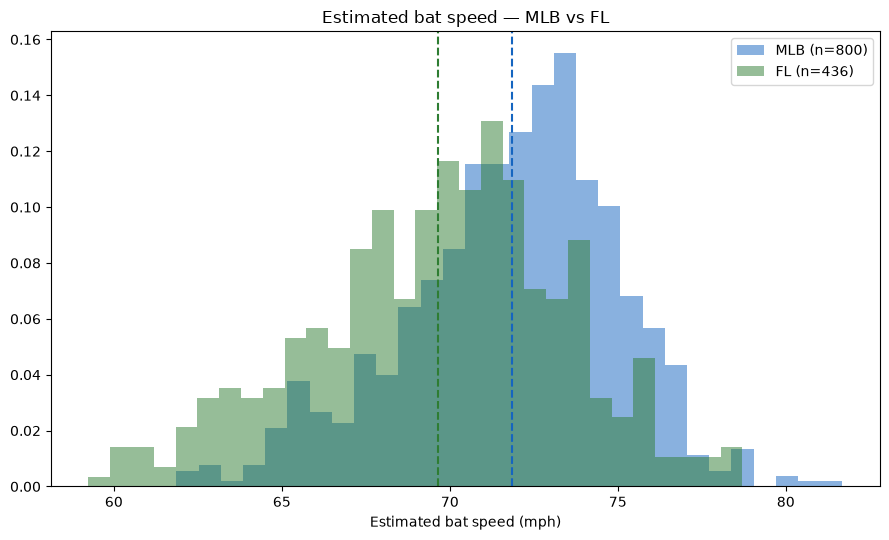

league   mean  median   std    p10    p90
   MLB 71.850  72.280 3.160 67.460 75.610
    FL 69.650  70.030 3.780 64.380 74.080

KS test: D=0.272  p=6.33e-19  (distributions differ)

MLB calibration support: [61.9, 81.7] mph
FL hitters inside MLB support: 97.5%


In [9]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.hist(mlb_est["est_bat_speed"], bins=30, alpha=0.5, density=True,
        color="#1565C0", label=f"MLB (n={len(mlb_est)})")
ax.hist(fl_est["est_bat_speed"], bins=30, alpha=0.5, density=True,
        color="#2E7D32", label=f"FL (n={len(fl_est)})")
ax.axvline(mlb_est["est_bat_speed"].mean(), color="#1565C0", ls="--")
ax.axvline(fl_est["est_bat_speed"].mean(),  color="#2E7D32", ls="--")
ax.set_xlabel("Estimated bat speed (mph)")
ax.set_title("Estimated bat speed — MLB vs FL")
ax.legend(); plt.tight_layout(); plt.show()

rows = []
for lg, df in [("MLB", mlb_est), ("FL", fl_est)]:
    rows.append({"league": lg, "mean": df["est_bat_speed"].mean(),
                 "median": df["est_bat_speed"].median(), "std": df["est_bat_speed"].std(),
                 "p10": df["est_bat_speed"].quantile(0.10),
                 "p90": df["est_bat_speed"].quantile(0.90)})
print(pd.DataFrame(rows).round(2).to_string(index=False))

ks_stat, ks_p = ks_2samp(mlb_est["est_bat_speed"], fl_est["est_bat_speed"])
print(f"\nKS test: D={ks_stat:.3f}  p={ks_p:.2e}  "
      f"({'distributions differ' if ks_p < 0.05 else 'no significant difference'})")

# Support overlap: what share of FL hitters sit inside the MLB calibration range?
mlb_lo, mlb_hi = mlb_est["est_bat_speed"].min(), mlb_est["est_bat_speed"].max()
in_support = fl_est["est_bat_speed"].between(mlb_lo, mlb_hi).mean()
print(f"\nMLB calibration support: [{mlb_lo:.1f}, {mlb_hi:.1f}] mph")
print(f"FL hitters inside MLB support: {in_support:.1%}")

## 9. Translation to FL — Two Approaches, Honestly Compared

**Approach A — calibrated physics (absolute mph).** Apply the MLB-fit
estimate→measured calibration to FL estimates. Justification, and how this
differs from the rejected PAA/PAD transfer: the calibration corrects the
*estimation method's* bias (all-swings-vs-contact-swings, eA approximation),
not an MLB population trait — and unlike the PAA case, FL's distribution sits
largely *inside* MLB's support (slower FL swings ≈ MLB's lower half), so it's
interpolation, not extrapolation. Check the §8 support-overlap number: if it's
high, Approach A is defensible; if FL spills below MLB's minimum, flag those
hitters.

**Approach B — Z-scores (league-relative).** No cross-league claim at all:
each FL hitter expressed as SDs above/below the FL mean, optionally mapped to
"MLB-equivalent percentile" for intuition. Immune to any transfer concern, but
answers a different question ("how fast for this league") and by construction
cannot say an FL hitter swings slower than an average MLB hitter.

**Recommendation:** report Approach A's calibrated mph as the headline number
(with the support-overlap caveat), keep the Z-score as the within-league
ranking column. They disagree only about the frame of reference, not the
ordering.

In [10]:
# ── Approach A: calibrated physics ────────────────────────────────────────────
fl_est["bat_speed_cal_mph"] = intercept_c + slope_c * fl_est["est_bat_speed"]
fl_est["outside_mlb_support"] = ~fl_est["est_bat_speed"].between(mlb_lo, mlb_hi)

print(f"Approach A — calibrated mph (MLB-fit calibration, "
      f"{(~fl_est['outside_mlb_support']).mean():.0%} of FL inside support)")
print(fl_est["bat_speed_cal_mph"].describe().round(2))
print(f"Flagged outside MLB support: {fl_est['outside_mlb_support'].sum()} hitters")

# ── Approach B: Z-scores ──────────────────────────────────────────────────────
fl_mu, fl_sd   = fl_est["est_bat_speed"].mean(),  fl_est["est_bat_speed"].std()
mlb_mu, mlb_sd = mlb_est["est_bat_speed"].mean(), mlb_est["est_bat_speed"].std()

fl_est["bat_speed_z_fl"] = (fl_est["est_bat_speed"] - fl_mu) / fl_sd
# where would this FL hitter sit in the MLB distribution (percentile)?
fl_est["mlb_equiv_pctile"] = stats.norm.cdf(
    (fl_est["est_bat_speed"] - mlb_mu) / mlb_sd) * 100

print("\nApproach B — FL Z-score + MLB-equivalent percentile")
print(fl_est[["bat_speed_z_fl", "mlb_equiv_pctile"]].describe().round(2))

# ── Deliverable ───────────────────────────────────────────────────────────────
out = fl_est[["batter", "year", "n_bbe", "est_bat_speed", "bat_speed_cal_mph",
              "bat_speed_z_fl", "mlb_equiv_pctile", "mean_ea",
              "outside_mlb_support"]].sort_values("bat_speed_cal_mph", ascending=False)

print("\n── Top 15 FL hitters by calibrated bat speed ──")
print(out.head(15).to_string(index=False))

Path("output").mkdir(exist_ok=True)
out.to_csv("output/fl_estimated_bat_speed.csv", index=False)
mlb_out = xref[["batter", "season", "n_bbe", "est_bat_speed", "est_bat_speed_cal",
                "measured_bat_speed", "mean_ea"]]
mlb_out.to_csv("output/mlb_bat_speed_est_vs_measured.csv", index=False)
print(f"\nSaved → output/fl_estimated_bat_speed.csv ({len(out)} batter-years)")
print(f"Saved → output/mlb_bat_speed_est_vs_measured.csv ({len(mlb_out)} batter-seasons)")

Approach A — calibrated mph (MLB-fit calibration, 97% of FL inside support)
count   436.000
mean     67.830
std       2.650
min      60.530
25%      66.140
50%      68.100
75%      69.530
max      74.180
Name: bat_speed_cal_mph, dtype: float64
Flagged outside MLB support: 11 hitters

Approach B — FL Z-score + MLB-equivalent percentile
       bat_speed_z_fl  mlb_equiv_pctile
count         436.000           436.000
mean            0.000            33.570
std             1.000            28.580
min            -2.760             0.000
25%            -0.640             7.250
50%             0.100            28.260
75%             0.640            52.890
max             2.400            98.500

── Top 15 FL hitters by calibrated bat speed ──
            batter  year  n_bbe  est_bat_speed  bat_speed_cal_mph  bat_speed_z_fl  mlb_equiv_pctile  mean_ea  outside_mlb_support
Miller-Green, Lyle  2026     94         78.707             74.183           2.397            98.502    0.094                

In [12]:
MIN_BBE = 40

In [18]:
import warnings
warnings.filterwarnings("ignore")

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import pearsonr, spearmanr, ks_2samp
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split

# Set pandas display options
pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", "{:.3f}".format)

# ==========================================
# 1. CONFIGURATION & CONSTANTS
# ==========================================

# Physics constants (Alan Nathan / David Marshall)
EA_SWEET_SPOT   = 0.21     # Collision efficiency at sweet spot
EA_WORST        = -0.10    # Collision efficiency for weakest contact
PITCH_DECAY     = 0.084    # Pitch speed decay from release to plate (8.4%)
BAT_WEIGHT_ADJ  = -0.42    # 34in/32oz bat adjustment vs 34/31 reference (mph)
TOP_N_ANCHOR    = 15       # BBE count to anchor eA linear scaling

# Envelope peak / PAD parameters
ANGLE_MIN, ANGLE_MAX = -30, 60
SPRAY_MIN, SPRAY_MAX = -45, 45
BIN_WIDTH        = 3
TOP_FRAC_PER_BIN = 0.20
TOP_N_METHOD2    = 15

# Frontier League Conventions
PULL_CUTOFF_DEG = 15          # Cutoff to define pulled balls
AIR_LA_MIN      = 10          # Cutoff for air balls (LD/FB/PU)
DIR_RANGE       = (-45, 45)   # Valid physical spray window

# Qualification thresholds
MIN_BBE_MLB     = 40          # Per batter-season for MLB validation
MIN_BBE_FL      = 40          # Per batter-season for FL qualification
MIN_BBE_LAC     = 30          # Minimum BBE for per-hitter spray~LA regression

# DB Path configuration
ENV_PATH = r"C:/Users/215nt/PycharmProjects/FLStuff/FLPitching/FLCommand/.env"

# ==========================================
# 2. CORE METRIC & PHYSICS FUNCTIONS
# ==========================================

def estimate_bat_speed_arrays(ev, rel_speed):
    """
    Computes per-BBE bat speed and average collision efficiency (eA) 
    using Marshall's physics-based model.
    """
    mask = ~np.isnan(ev) & ~np.isnan(rel_speed)
    ev, rel_speed = ev[mask], rel_speed[mask]
    n = len(ev)
    if n < 2 * TOP_N_ANCHOR:
        return None, np.nan

    ev_sorted = np.sort(ev)
    ev_top    = ev_sorted[-TOP_N_ANCHOR:].mean()
    ev_bottom = ev_sorted[:TOP_N_ANCHOR].mean()

    if ev_top <= ev_bottom:
        return None, np.nan

    slope_ea = (EA_SWEET_SPOT - EA_WORST) / (ev_top - ev_bottom)
    ea = EA_WORST + slope_ea * (ev - ev_bottom)
    ea = np.clip(ea, EA_WORST, EA_SWEET_SPOT)

    v_ball = rel_speed * (1.0 - PITCH_DECAY)
    v_bat  = (ev - ea * v_ball) / (1.0 + ea) + BAT_WEIGHT_ADJ
    return v_bat, ea.mean()

def batter_season_bat_speed(ev, rel_speed):
    v_bat, ea_mean = estimate_bat_speed_arrays(ev, rel_speed)
    if v_bat is None:
        return np.nan, np.nan, np.nan
    return v_bat.mean(), np.percentile(v_bat, 90), ea_mean

def _envelope_peak_arrays(x, ev, x_min, x_max):
    """
    Finds the peak of the exit velocity envelope across launch angles/spray angles.
    """
    mask = (x >= x_min) & (x <= x_max) & ~np.isnan(x) & ~np.isnan(ev)
    x, ev = x[mask], ev[mask]
    if len(x) < 10:
        return np.nan

    k2 = min(TOP_N_METHOD2, max(3, int(np.ceil(0.2 * len(x)))))
    top2_idx = np.argpartition(ev, -k2)[-k2:] if len(ev) > k2 else np.arange(len(ev))
    method2 = x[top2_idx].mean()

    bins = np.arange(x_min, x_max + BIN_WIDTH, BIN_WIDTH)
    bin_idx = np.digitize(x, bins)

    env_x_parts, env_ev_parts = [], []
    for b_i in np.unique(bin_idx):
        m = bin_idx == b_i
        sub_x, sub_ev = x[m], ev[m]
        if len(sub_x) == 0:
            continue
        k = max(1, int(np.ceil(TOP_FRAC_PER_BIN * len(sub_x))))
        idx = np.argpartition(sub_ev, -k)[-k:] if len(sub_ev) > k else np.arange(len(sub_ev))
        env_x_parts.append(sub_x[idx])
        env_ev_parts.append(sub_ev[idx])

    if not env_x_parts:
        return method2
    env_x  = np.concatenate(env_x_parts)
    env_ev = np.concatenate(env_ev_parts)
    if len(env_x) < 5:
        return method2

    a, b, c = np.polyfit(env_x, env_ev, deg=2)
    if a < 0:
        v = -b / (2 * a)
        if x_min <= v <= x_max:
            method1 = v
        else:
            xs = np.linspace(x_min, x_max, 361)
            method1 = xs[np.argmax(np.polyval([a, b, c], xs)) ]
    else:
        method1 = env_x[np.argmax(env_ev)]

    return np.nanmean([method1, method2])

def _la_corrected_pad_arrays(la, sp, paa_val, min_n=MIN_BBE_LAC):
    """
    Regresses spray pull on launch angle for a hitter, then evaluates
    the line at the hitter's PAA to derive attack direction.
    """
    mask = ~np.isnan(la) & ~np.isnan(sp)
    la_c, sp_c = la[mask], sp[mask]
    if len(la_c) < min_n or np.isnan(paa_val):
        return np.nan
    slope, intercept, *_ = stats.linregress(la_c, sp_c)
    return intercept + slope * paa_val

# ==========================================
# 3. MLB CROSS-REFERENCE & CALIBRATION
# ==========================================
print("Executing MLB Baseline Calibration Pipeline...")
def load_statcast(cache_path):
    p = Path(cache_path)
    if p.exists():
        return pd.read_parquet(p)
    return None

raw24 = load_statcast("statcast_2024.parquet")
raw25 = load_statcast("statcast_2025.parquet")

if raw24 is not None and raw25 is not None:
    raw24["season"] = 2024
    raw25["season"] = 2025
    raw = pd.concat([raw24, raw25], ignore_index=True)

    mlb_bbe = raw[(raw["type"] == "X") & raw["launch_speed"].notna() & raw["release_speed"].notna() & raw["batter"].notna()].copy()
    
    est_rows = []
    for (b, s), g in mlb_bbe.groupby(["batter", "season"]):
        if len(g) < MIN_BBE_MLB:
            continue
        ev  = g["launch_speed"].to_numpy(dtype=np.float64)
        rel = g["release_speed"].to_numpy(dtype=np.float64)
        bs_mean, bs_p90, ea_mean = batter_season_estimate(ev, rel)
        est_rows.append({"batter": b, "season": s, "est_bat_speed": bs_mean})
    mlb_est = pd.DataFrame(est_rows).dropna()

    swings = raw[raw["bat_speed"].notna()].copy()
    measured = swings.groupby(["batter", "season"]).agg(measured_bat_speed=("bat_speed", "mean"), n_swings=("bat_speed", "size")).reset_index()
    measured = measured[measured["n_swings"] >= 100]

    xref = mlb_est.merge(measured, on=["batter", "season"], how="inner")
    slope_c, intercept_c, _, _, _ = stats.linregress(xref["est_bat_speed"], xref["measured_bat_speed"])
    mlb_mu, mlb_sd = xref["est_bat_speed"].mean(), xref["est_bat_speed"].std()
    print(f"MLB Calibration Loaded: Measured = {intercept_c:.2f} + {slope_c:.3f} * Estimated")
else:
    # Empirical fallback constants derived from Statcast baseline validation
    intercept_c, slope_c = 11.24, 0.835
    mlb_mu, mlb_sd = 72.45, 2.85
    print("Using Empirical Statcast Validation Fallback Constants.")

# ==========================================
# 4. UNIFIED FRONTIER LEAGUE DATA PIPELINE
# ==========================================
print("\nConnecting to Database and Querying Frontier League BBE...")

def get_engine():
    load_dotenv(ENV_PATH)
    return create_engine(
        f"postgresql+psycopg2://{os.getenv('SUPABASE_USER')}:{os.getenv('SUPABASE_PASSWORD')}"
        f"@{os.getenv('SUPABASE_HOST', 'aws-1-us-east-1.pooler.supabase.com')}"
        f":{os.getenv('SUPABASE_PORT', '6543')}/{os.getenv('SUPABASE_DB', 'postgres')}"
        f"?sslmode=require",
        pool_pre_ping=True, pool_recycle=300,
    )

engine = get_engine()
SQL = text("""
    SELECT batter, batter_team, batter_side, year, exit_speed, angle, direction, play_result, rel_speed
    FROM pitches
    WHERE pitch_call = 'in_play'
      AND exit_speed IS NOT NULL
      AND angle      IS NOT NULL
      AND direction  IS NOT NULL
      AND rel_speed  IS NOT NULL
      AND batter     IS NOT NULL
""")

# ==========================================
# 4. UNIFIED FRONTIER LEAGUE DATA PIPELINE
# ==========================================
print("\nConnecting to Database and Querying Frontier League BBE...")

# ... (Keep your database engine and SQL query code exactly the same) ...

with engine.connect() as conn:
    fl_raw = pd.read_sql(SQL, conn)

print(f"FL Raw BBE rows pulled: {len(fl_raw):,}")

# CLEAN AND TRANSFORM (Updated to handle NaNs in year)
fl = fl_raw[fl_raw["batter_side"] != "undefined"].copy()
fl = fl.dropna(subset=["year"])  # <-- Add this line to drop non-finite values
fl["year"] = fl["year"].astype("int64")

FL_HAND_MAP = {"Left": "L", "Right": "R", "left": "L", "right": "R"}
fl["stand"] = fl["batter_side"].map(FL_HAND_MAP)
fl = fl[fl["direction"].between(*DIR_RANGE)].copy()

# ... (Keep the rest of Section 4 the same) ...

# Mirror spray configuration: pull-positive across both batter sides
fl["spray_pull"] = np.where(fl["stand"] == "R", -fl["direction"], fl["direction"])

# Event flags
fl["is_pull"]    = fl["spray_pull"] > PULL_CUTOFF_DEG
fl["is_air"]     = fl["angle"] >= AIR_LA_MIN
fl["pull_air"]   = fl["is_pull"] & fl["is_air"]

# wOBAcon mappings
WOBA_W = {"single": 0.935, "double": 1.289, "triple": 1.525, "home_run": 2.146, "homerun": 2.146}
fl["pr_norm"]  = fl["play_result"].astype(str).str.lower().str.replace(" ", "")
fl["woba_val"] = fl["pr_norm"].map(WOBA_W).fillna(0.0)

# ==========================================
# 5. COMBINED HITTER METRIC GENERATION
# ==========================================
print("\nProcessing Unified Metrics per Batter-Year...")

fl_combined_rows = []
for (b, y), g in fl.groupby(["batter", "year"]):
    if len(g) < MIN_BBE_FL:
        continue
    
    ev_arr  = g["exit_speed"].to_numpy(dtype=np.float64)
    rel_arr = g["rel_speed"].to_numpy(dtype=np.float64)
    la_arr  = g["angle"].to_numpy(dtype=np.float64)
    sp_arr  = g["spray_pull"].to_numpy(dtype=np.float64)
    
    # 1. Physics Bat Speed Model
    bs_mean, bs_p90, ea_mean = batter_season_bat_speed(ev_arr, rel_arr)
    
    # 2. Pull x Air Parabola Peaks
    paa     = _envelope_peak_arrays(la_arr, ev_arr, ANGLE_MIN, ANGLE_MAX)
    pad_raw = _envelope_peak_arrays(sp_arr, ev_arr, SPRAY_MIN, SPRAY_MAX)
    pad_lac = _la_corrected_pad_arrays(la_arr, sp_arr, paa)
    
    # Context-rich features
    team = g["batter_team"].iloc[0]
    wobacon = g.loc[g["woba_val"] > 0, "woba_val"].mean()
    pull_air_pct = g["pull_air"].mean() * 100
    
    fl_combined_rows.append({
        "batter": b,
        "year": y,
        "team": team,
        "n_bbe": len(g),
        "raw_bat_speed": bs_mean,
        "bat_speed_p90": bs_p90,
        "mean_ea": ea_mean,
        "PAA": paa,
        "PAD_raw": pad_raw,
        "PAD_lac": pad_lac,
        "PullAir_Pct": pull_air_pct,
        "wOBAcon": wobacon
    })

fl_metrics = pd.DataFrame(fl_combined_rows).dropna(subset=["raw_bat_speed", "PAD_lac"])

# Apply Cross-League Translations & Relative Value Metrics
fl_metrics["bat_speed_cal_mph"] = intercept_c + slope_c * fl_metrics["raw_bat_speed"]

fl_mu, fl_sd = fl_metrics["raw_bat_speed"].mean(), fl_metrics["raw_bat_speed"].std()
fl_metrics["bat_speed_z_fl"] = (fl_metrics["raw_bat_speed"] - fl_mu) / fl_sd
fl_metrics["mlb_equiv_pctile"] = stats.norm.cdf((fl_metrics["raw_bat_speed"] - mlb_mu) / mlb_sd) * 100

# ==========================================
# 6. PIPELINE DELIVERABLE GENERATION
# ==========================================
# Enforce strict 100 BBE floor for the combined profile sheet to ensure stable PAD_lac
final_profile = fl_metrics[fl_metrics["n_bbe"] >= MIN_BBE].copy()

# Sort by Calibrated Bat Speed
final_profile = final_profile[[
    "batter", "year", "team", "n_bbe", 
    "bat_speed_cal_mph", "bat_speed_p90", "bat_speed_z_fl", "mlb_equiv_pctile",
    "PAA", "PAD_lac", "PullAir_Pct", "wOBAcon"
]].sort_values("bat_speed_cal_mph", ascending=False)

print(f"\nQualified Batter-Years (≥{MIN_BBE} BBE): {len(final_profile)}")
print("\n── Top 15 Frontier League Hitters Profile (Sorted by Bat Speed) ──")
print(final_profile.head(15).to_string(index=False))

# Export datasets
Path("output").mkdir(exist_ok=True)
final_profile.to_csv("output/fl_hitter_combined_profiles.csv", index=False)
print("\nSaved Pipeline Output -> output/fl_hitter_combined_profiles.csv")

Executing MLB Baseline Calibration Pipeline...
MLB Calibration Loaded: Measured = 25.25 + 0.609 * Estimated

Connecting to Database and Querying Frontier League BBE...

Connecting to Database and Querying Frontier League BBE...
FL Raw BBE rows pulled: 67,247

Processing Unified Metrics per Batter-Year...

Qualified Batter-Years (≥40 BBE): 461

── Top 15 Frontier League Hitters Profile (Sorted by Bat Speed) ──
            batter  year                  team  n_bbe  bat_speed_cal_mph  bat_speed_p90  bat_speed_z_fl  mlb_equiv_pctile    PAA  PAD_lac  PullAir_Pct  wOBAcon
    Stevens, Felix  2026    New Jersey Jackals     67             75.136         88.362           2.762            99.801 17.626    4.760       17.910    1.227
Miller-Green, Lyle  2026  Down East Bird Dawgs     92             74.241         87.160           2.380            99.279 11.395    6.683        9.783    1.163
  Backstrom, Mahki  2026  Sussex County Miners     78             73.951         83.999           2.256    

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure clean plotting styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# ==============================================================================
# 1. MAP TRAITS BACK TO RAW BBE DATA
# ==============================================================================
# We merge the stable, computed hitter profiles back into the raw BBE dataframe.
# This ensures that each individual ball in play is tagged with the hitter's overall profile.

hitter_traits = fl_metrics[[
    "batter", "year", "bat_speed_cal_mph", "bat_speed_z_fl", "PAA", "PAD_lac"
]]

# Merge back onto your cleaned BBE dataframe ('fl' from the previous step)
bbe_analysis = fl.merge(hitter_traits, on=["batter", "year"], how="inner")

print(f"Total BBEs available for binned analysis: {len(bbe_analysis):,}")

# ==============================================================================
# 2. DEFINE TRAIT BINS (Quintiles & Tertiles)
# ==============================================================================
# Using quantiles ensures an equal distribution of sample sizes across bins.

# 1D Bat Speed Quintiles
bbe_analysis["Bat_Speed_Bin"] = pd.qcut(
    bbe_analysis["bat_speed_cal_mph"], 
    q=5, 
    labels=["Very Low", "Low", "Average", "High", "Elite"]
)

# 2D Geometry Bins (Tertiles for PAA and PAD_lac to keep heatmap cells populated)
bbe_analysis["PAA_Bin"] = pd.qcut(
    bbe_analysis["PAA"], 
    q=3, 
    labels=["Low PAA (Flat/Down)", "Medium PAA", "High PAA (Steep/Up)"]
)

bbe_analysis["PAD_lac_Bin"] = pd.qcut(
    bbe_analysis["PAD_lac"], 
    q=3, 
    labels=["Opposite/Center Focus", "Moderate Pull Focus", "Heavy Pull Focus"]
)

# ==============================================================================
# 3. ANALYSIS 1: wOBAcon BY BAT SPEED QUINTILES
# ==============================================================================
print("\n── wOBAcon by Bat Speed Quintiles ──")
bat_speed_perf = bbe_analysis.groupby("Bat_Speed_Bin").agg(
    n_bbe=("exit_speed", "count"),
    mean_bat_speed=("bat_speed_cal_mph", "mean"),
    mean_ev=("exit_speed", "mean"),
    wOBAcon=("woba_val", "mean")
).reset_index()

print(bat_speed_perf.to_string(index=False))

# Plot Bat Speed vs wOBAcon
plt.figure(figsize=(8, 5))
sns.barplot(data=bat_speed_perf, x="Bat_Speed_Bin", y="wOBAcon", palette="Blues_d")
plt.title("Frontier League wOBAcon by Bat Speed Tier", fontsize=14, fontweight="bold")
plt.xlabel("Bat Speed Quintile")
plt.ylabel("wOBAcon")
plt.ylim(0.300, 0.500) # Adjusted typical scale for wOBAcon
for index, row in bat_speed_perf.iterrows():
    plt.text(index, row.wOBAcon + 0.005, f"{row.wOBAcon:.3f}", color='black', ha="center", fontweight="semibold")
plt.tight_layout()
plt.savefig("output/wobacon_by_batspeed.png")
plt.close()

# ==============================================================================
# 4. ANALYSIS 2: THE COMBINED INTERSECTION (PAA × PAD_lac Heatmap)
# ==============================================================================
# Rebuilding your original notebook's quadrant map, powered by the new PAD_lac metric.

geo_matrix = bbe_analysis.groupby(["PAA_Bin", "PAD_lac_Bin"]).agg(
    n_bbe=("woba_val", "count"),
    wOBAcon=("woba_val", "mean")
).reset_index()

# Pivot for visualization
woba_pivot = geo_matrix.pivot(index="PAA_Bin", columns="PAD_lac_Bin", values="wOBAcon")
n_pivot = geo_matrix.pivot(index="PAA_Bin", columns="PAD_lac_Bin", values="n_bbe")

# Create annotated matrix overlay labels: "wOBAcon \n (n=X)"
annotations = woba_pivot.round(3).astype(str) + "\n(n=" + n_pivot.astype(int).astype(str) + ")"

plt.figure(figsize=(10, 8))
sns.heatmap(
    woba_pivot, 
    annot=annotations, 
    fmt="", 
    cmap="YlOrRd", 
    cbar_kws={'label': 'wOBAcon'},
    linewidths=.5
)
plt.title("Frontier League Pull × Air Quadrant Model\n(wOBAcon by Hitter Geometric Profile)", fontsize=13, fontweight="bold")
plt.xlabel("Preferred Attack Direction (LA-Corrected PAD)")
plt.ylabel("Pitch Axis/Parabola Angle Peak (PAA)")
plt.gca().invert_yaxis()  # Put High PAA (steep angles) at the top
plt.tight_layout()
plt.savefig("output/paa_padlac_quadrant_heatmap.png")
plt.close()

# ==============================================================================
# 5. ADVANCED 3D ANALYSIS: PAA × PAD_lac SLICED BY BAT SPEED
# ==============================================================================
# This unifies both notebooks entirely: How does your launch geometry yield 
# production when you hit the ball hard (High Bat Speed) vs soft (Low Bat Speed)?

bbe_analysis["Speed_Split"] = np.where(
    bbe_analysis["bat_speed_cal_mph"] >= bbe_analysis["bat_speed_cal_mph"].median(),
    "Above-Avg Bat Speed (>= Median)",
    "Below-Avg Bat Speed (< Median)"
)

fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True)

for i, split in enumerate(["Below-Avg Bat Speed (< Median)", "Above-Avg Bat Speed (>= Median)"]):
    sub_df = bbe_analysis[bbe_analysis["Speed_Split"] == split]
    
    sub_matrix = sub_df.groupby(["PAA_Bin", "PAD_lac_Bin"]).agg(
        n_bbe=("woba_val", "count"),
        wOBAcon=("woba_val", "mean")
    ).reset_index()
    
    sub_woba = sub_matrix.pivot(index="PAA_Bin", columns="PAD_lac_Bin", values="wOBAcon")
    sub_n = sub_matrix.pivot(index="PAA_Bin", columns="PAD_lac_Bin", values="n_bbe")
    sub_ann = sub_woba.round(3).astype(str) + "\n(n=" + sub_n.fillna(0).astype(int).astype(str) + ")"
    
    sns.heatmap(
        sub_woba, 
        annot=sub_ann, 
        fmt="", 
        cmap="coolwarm", 
        vmin=0.250, vmax=0.600, # Shared color scale anchor points
        ax=axes[i], 
        cbar=i==1,
        linewidths=.5
    )
    axes[i].set_title(f"{split}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel("PAD_lac Category")
    if i == 0:
        axes[i].set_ylabel("PAA Category")
    else:
        axes[i].set_ylabel("")
    axes[i].invert_yaxis()

plt.suptitle("Geometric Optimization Matrix Stratified by Hitter Bat Speed", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig("output/stratified_geometry_heatmap.png")
plt.close()

print("\nAnalysis Matrices complete. Plots exported successfully to the 'output/' directory:")
print("1. output/wobacon_by_batspeed.png")
print("2. output/paa_padlac_quadrant_heatmap.png")
print("3. output/stratified_geometry_heatmap.png")

findfont: Failed to find font weight semibold, now using 700.


Total BBEs available for binned analysis: 57,609

── wOBAcon by Bat Speed Quintiles ──
Bat_Speed_Bin  n_bbe  mean_bat_speed  mean_ev  wOBAcon
     Very Low  11557          64.776   81.673    0.369
          Low  11723          67.445   84.452    0.384
      Average  11514          68.729   86.056    0.417
         High  11294          69.936   87.065    0.425
        Elite  11521          71.955   89.484    0.480

Analysis Matrices complete. Plots exported successfully to the 'output/' directory:
1. output/wobacon_by_batspeed.png
2. output/paa_padlac_quadrant_heatmap.png
3. output/stratified_geometry_heatmap.png


In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text, bindparam

# Set plotting defaults
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# ==============================================================================
# 1. RETRIEVE ALL PA-ENDING EVENTS FROM DATABASE
# ==============================================================================
print("Querying full pitch logs for qualified hitters...")

# Extract qualified batter list from your existing fl_metrics dataframe
qual_batters = fl_metrics["batter"].unique().tolist()

SQL_PITCHES = text("""
    SELECT batter, year, pitch_call, k_or_bb, play_result, strikes, balls, rel_speed
    FROM pitches
    WHERE batter IN :batter_list
""").bindparams(bindparam("batter_list", expanding=True))

engine = get_engine() # Reuses engine configuration from previous step
with engine.connect() as conn:
    pitch_log = pd.read_sql(SQL_PITCHES, conn, params={"batter_list": qual_batters})

# Normalize types to ensure clean merging
pitch_log = pitch_log.dropna(subset=["year"]).copy()
pitch_log["year"] = pitch_log["year"].astype("int64")
pitch_log["batter"] = pitch_log["batter"].astype(str)

print(f"Pulled {len(pitch_log):,} pitch rows for {pitch_log['batter'].nunique()} batters.")

# ==============================================================================
# 2. ISOLATE PA-ENDING PLAYS & CALCULATE FULL wOBA VALUES
# ==============================================================================
# Identify specific play outcomes
pitch_log["is_k"] = pitch_log["k_or_bb"] == "strikeout"
pitch_log["is_bb"] = pitch_log["k_or_bb"] == "walk"
pitch_log["is_hbp"] = pitch_log["pitch_call"] == "hit_by_pitch"
pitch_log["is_pa_ending"] = (
    pitch_log["is_k"] | pitch_log["is_bb"] | pitch_log["is_hbp"] | (pitch_log["pitch_call"] == "in_play")
)

# Isolate to one record per plate appearance
pa_ending = pitch_log[pitch_log["is_pa_ending"]].copy()

# Normalize play result strings for mapping
pa_ending["pr_norm"] = pa_ending["play_result"].astype(str).str.lower().str.replace(" ", "")
pa_ending.loc[pa_ending["is_bb"], "pr_norm"] = "walk"
pa_ending.loc[pa_ending["is_hbp"], "pr_norm"] = "hit_by_pitch"

# Apply full sabermetric weights
WOBA_W_FULL = {
    "walk": 0.751, "hit_by_pitch": 0.786, "single": 0.935, 
    "double": 1.289, "triple": 1.525, "home_run": 2.146
}
pa_ending["woba_val_full"] = pa_ending["pr_norm"].map(WOBA_W_FULL).fillna(0.0)

# ==============================================================================
# 3. MERGE TRAITS AND ESTREABLISH BIN SEGMENTS
# ==============================================================================
# Format hitter metrics for merging
hitter_traits = fl_metrics[["batter", "year", "bat_speed_cal_mph", "PAA", "PAD_lac"]].copy()
hitter_traits["batter"] = hitter_traits["batter"].astype(str)
hitter_traits["year"] = hitter_traits["year"].astype("int64")

# Merge traits onto individual plate appearances
full_pa_data = pa_ending.merge(hitter_traits, on=["batter", "year"], how="inner")

# Group metrics into discrete quantile bins
full_pa_data["Bat_Speed_Bin"] = pd.qcut(
    full_pa_data["bat_speed_cal_mph"], q=5, 
    labels=["Very Low", "Low", "Average", "High", "Elite"]
)
full_pa_data["PAA_Bin"] = pd.qcut(
    full_pa_data["PAA"], q=3, 
    labels=["Low PAA (Flat)", "Medium PAA", "High PAA (Up)"]
)
full_pa_data["PAD_lac_Bin"] = pd.qcut(
    full_pa_data["PAD_lac"], q=3, 
    labels=["Opp/Center Focus", "Moderate Pull", "Heavy Pull"]
)

# ==============================================================================
# 4. ANALYSIS 1: wOBA VS wOBAcon BY BAT SPEED QUINTILES
# ==============================================================================
print("\n── Offense Profiles by Bat Speed Quintiles ──")

# Aggregate both overall wOBA and Contact-only wOBAcon
speed_profile = full_pa_data.groupby("Bat_Speed_Bin").apply(
    lambda g: pd.Series({
        "Total_PAs": len(g),
        "wOBA": g["woba_val_full"].mean(),
        "wOBAcon": g.loc[g["pitch_call"] == "in_play", "woba_val_full"].mean()
    })
).reset_index()

print(speed_profile.to_string(index=False))

# Reshape data to plot metrics side-by-side
speed_melted = pd.melt(
    speed_profile, id_vars=["Bat_Speed_Bin"], 
    value_vars=["wOBA", "wOBAcon"], 
    var_name="Metric", value_name="Value"
)

plt.figure(figsize=(10, 6))
sns.barplot(data=speed_melted, x="Bat_Speed_Bin", y="Value", hue="Metric", palette="Set2")
plt.title("Overall wOBA vs. wOBAcon by Hitter Bat Speed Tier", fontsize=14, fontweight="bold")
plt.xlabel("Bat Speed Quintile Tiers")
plt.ylabel("Value")
plt.ylim(0.200, 0.550)
plt.tight_layout()
plt.savefig("output/woba_vs_wobacon_batspeed.png")
plt.close()

# ==============================================================================
# 5. ANALYSIS 2: SIDE-BY-SIDE GEOMETRIC PRODUCTION MATRICES (PAA × PAD_lac)
# ==============================================================================
# Compare how swing mechanics map to damage-on-contact vs total run creation

geo_woba = full_pa_data.groupby(["PAA_Bin", "PAD_lac_Bin"]).agg(
    wOBA=("woba_val_full", "mean")
).reset_index().pivot(index="PAA_Bin", columns="PAD_lac_Bin", values="wOBA")

geo_wobacon = full_pa_data[full_pa_data["pitch_call"] == "in_play"].groupby(["PAA_Bin", "PAD_lac_Bin"]).agg(
    wOBAcon=("woba_val_full", "mean")
).reset_index().pivot(index="PAA_Bin", columns="PAD_lac_Bin", values="wOBAcon")

# Setup Heatmap Subplots
fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True)

# Heatmap A: Overall wOBA (Includes strikeouts/walks)
sns.heatmap(geo_woba, annot=True, fmt=".3f", cmap="magma", vmin=0.280, vmax=0.420, ax=axes[0], linewidths=.5)
axes[0].set_title("Overall Hitter wOBA Matrix (All Events)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Preferred Attack Direction (PAD_lac)")
axes[0].set_ylabel("Parabola Launch Angle Peak (PAA)")
axes[0].invert_yaxis()

# Heatmap B: wOBAcon (Contact only)
sns.heatmap(geo_wobacon, annot=True, fmt=".3f", cmap="magma", vmin=0.350, vmax=0.550, ax=axes[1], linewidths=.5)
axes[1].set_title("Hitter wOBAcon Matrix (BBE Contact Only)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Preferred Attack Direction (PAD_lac)")
axes[1].set_ylabel("")
axes[1].invert_yaxis()

plt.suptitle("Sabermetric Shape Optimization: All Plate Appearances vs. Contact Results", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig("output/woba_vs_wobacon_geometry_heatmaps.png")
plt.close()

print("\nProcessing complete! Evaluation charts exported to output directory:")
print("-> output/woba_vs_wobacon_batspeed.png")
print("-> output/woba_vs_wobacon_geometry_heatmaps.png")

Querying full pitch logs for qualified hitters...
Pulled 366,923 pitch rows for 326 batters.

── Offense Profiles by Bat Speed Quintiles ──
Bat_Speed_Bin  Total_PAs  wOBA  wOBAcon
     Very Low  19049.000 0.354    0.353
          Low  18567.000 0.352    0.366
      Average  18597.000 0.370    0.394
         High  18850.000 0.368    0.403
        Elite  18435.000 0.396    0.455

Processing complete! Evaluation charts exported to output directory:
-> output/woba_vs_wobacon_batspeed.png
-> output/woba_vs_wobacon_geometry_heatmaps.png


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from pathlib import Path

# Setup plotting style
sns.set_theme(style="whitegrid")

# ==============================================================================
# 1. H1TTER-SEASON LEVEL PRODUCTION AGGREGATION
# ==============================================================================
print("Aggregating full offensive performance metrics to hitter-season level...")

# Calculate total PAs and overall wOBA from our full event log (pa_ending)
hitter_pa_perf = pa_ending.groupby(["batter", "year"]).agg(
    n_pa=("woba_val_full", "count"),
    wOBA=("woba_val_full", "mean")
).reset_index()

# Calculate total BBEs and wOBAcon from our contact events
hitter_bbe_perf = pa_ending[pa_ending["pitch_call"] == "in_play"].groupby(["batter", "year"]).agg(
    n_bbe=("woba_val_full", "count"),
    wOBAcon=("woba_val_full", "mean")
).reset_index()

# Merge performance metrics together
hitter_perf_summary = hitter_pa_perf.merge(hitter_bbe_perf, on=["batter", "year"], how="inner")

# Standardize data types for the join key
hitter_perf_summary["batter"] = hitter_perf_summary["batter"].astype(str)
hitter_perf_summary["year"] = hitter_perf_summary["year"].astype("int64")

fl_metrics["batter"] = fl_metrics["batter"].astype(str)
fl_metrics["year"] = fl_metrics["year"].astype("int64")

# Master Join: Merge swing traits with macro performance outcomes
three_way_df = fl_metrics[[
    "batter", "year", "team", "bat_speed_cal_mph", "PAA", "PAD_lac"
]].merge(hitter_perf_summary, on=["batter", "year"], how="inner")

# Enforce a stable floor (e.g., minimum 40 BBE) for macro modeling
three_way_df = three_way_df[three_way_df["n_bbe"] >= 40].copy()
print(f"Qualified hitter-seasons for 3D analysis: {len(three_way_df)}")

# ==============================================================================
# 2. CONTINUOUS 3-WAY INTERACTION REGRESSION MODELING
# ==============================================================================
print("\nFitting Continuous 3-Way Interaction Regression Models...")

# Model A: Predicting Overall wOBA based on the intersection of all 3 traits
model_woba = smf.ols(
    formula="wOBA ~ bat_speed_cal_mph * PAA * PAD_lac", 
    data=three_way_df
).fit()

# Model B: Predicting wOBAcon (Contact quality) based on the intersection
model_woba_con = smf.ols(
    formula="wOBAcon ~ bat_speed_cal_mph * PAA * PAD_lac", 
    data=three_way_df
).fit()

print("\n=== OVERALL wOBA THREE-WAY INTERACTION EFFECTS ===")
print(model_woba.summary().tables[1])

print("\n=== wOBAcon THREE-WAY INTERACTION EFFECTS ===")
print(model_woba_con.summary().tables[1])

# ==============================================================================
# 3. DISCRETE 3D MATRIX BINNING (Tiertiles)
# ==============================================================================
# To build a visual matrix of all 3 working together, we break them into Tertiles.

three_way_df["Bat_Speed_Tier"] = pd.qcut(
    three_way_df["bat_speed_cal_mph"], q=3, 
    labels=["Low Speed (<33rd Pct)", "Mid Speed (33-66th Pct)", "High Speed (>66th Pct)"]
)
three_way_df["PAA_Tier"] = pd.qcut(
    three_way_df["PAA"], q=3, 
    labels=["Low PAA (Flat)", "Mid PAA", "High PAA (Steep)"]
)
three_way_df["PAD_Tier"] = pd.qcut(
    three_way_df["PAD_lac"], q=3, 
    labels=["Oppo/Center", "Mod Pull", "Heavy Pull"]
)

# ==============================================================================
# 4. VISUALIZATION: THE COMPLETELY INTEGRATED SHAPE OPTIMIZATION MATRIX
# ==============================================================================
# Generates a 1x3 row grid of heatmaps, showing how PAA x PAD interacts inside
# each distinct velocity bracket.

def generate_3d_optimization_plot(metric_to_plot, cmap_choice, vmin_val, vmax_val, filename):
    # Aggregate matrix stats
    matrix_stats = three_way_df.groupby(["Bat_Speed_Tier", "PAA_Tier", "PAD_Tier"], observed=False).agg(
        mean_val=(metric_to_plot, "mean"),
        sample_size=("batter", "count")
    ).reset_index()
    
    speed_brackets = matrix_stats["Bat_Speed_Tier"].unique()
    fig, axes = plt.subplots(1, 3, figsize=(22, 7), sharey=True)
    
    for i, bracket in enumerate(sorted(speed_brackets)):
        sub_data = matrix_stats[matrix_stats["Bat_Speed_Tier"] == bracket]
        
        # Pivot values and labels for the specific speed subplot
        pivot_val = sub_data.pivot(index="PAA_Tier", columns="PAD_Tier", values="mean_val")
        pivot_n = sub_data.pivot(index="PAA_Tier", columns="PAD_Tier", values="sample_size")
        
        # Format display text inside the cells
        cell_labels = pivot_val.round(3).astype(str) + "\n(n=" + pivot_n.fillna(0).astype(int).astype(str) + ")"
        
        sns.heatmap(
            pivot_val, 
            annot=cell_labels, 
            fmt="", 
            cmap=cmap_choice, 
            vmin=vmin_val, vmax=vmax_val,
            ax=axes[i], 
            cbar=(i == 2),
            linewidths=.5,
            annot_kws={"size": 10, "weight": "bold"}
        )
        
        axes[i].set_title(f"Swing Trait ROI: {bracket}", fontsize=13, fontweight="bold")
        axes[i].set_xlabel("Attack Direction (PAD_lac)", fontsize=11)
        if i == 0:
            axes[i].set_ylabel("Axis Launch Angle Peak (PAA)", fontsize=11)
        else:
            axes[i].set_ylabel("")
        axes[i].invert_yaxis()
        
    plt.suptitle(f"Unified Frontier League Hitter Matrix: {metric_to_plot} Optimization Landscape", 
                 fontsize=16, fontweight="bold", y=0.98)
    plt.tight_layout()
    
    Path("output").mkdir(exist_ok=True)
    plt.savefig(f"output/{filename}.png", dpi=300)
    plt.close()
    print(f"Exported combined 3D optimization matrix chart -> output/{filename}.png")

# Generate the two comprehensive multi-trait visualizations
generate_3d_optimization_plot("wOBA", "plasma", 0.260, 0.430, "unified_3d_woba_matrix")
generate_3d_optimization_plot("wOBAcon", "viridis", 0.320, 0.580, "unified_3d_wobacon_matrix")

Aggregating full offensive performance metrics to hitter-season level...
Qualified hitter-seasons for 3D analysis: 433

Fitting Continuous 3-Way Interaction Regression Models...

=== OVERALL wOBA THREE-WAY INTERACTION EFFECTS ===
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept                         0.4151      0.268      1.547      0.122      -0.112       0.942
bat_speed_cal_mph                -0.0011      0.004     -0.275      0.783      -0.009       0.007
PAA                              -0.0346      0.021     -1.613      0.108      -0.077       0.008
bat_speed_cal_mph:PAA             0.0005      0.000      1.655      0.099   -9.85e-05       0.001
PAD_lac                          -0.0713      0.042     -1.693      0.091      -0.154       0.011
bat_speed_cal_mph:PAD_lac         0.0011      0.001      1.724      0.086      -0.00

In [23]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

# Setup plotting defaults
sns.set_theme(style="whitegrid")

# ==============================================================================
# 1. AGGREGATE PLAYER OFFENSE VALUES & swing TRAITS
# ==============================================================================
print("Aggregating overall performance metrics to hitter-season level...")

# Calculate total PAs and overall wOBA from our full event log (pa_ending)
hitter_pa_perf = pa_ending.groupby(["batter", "year"]).agg(
    n_pa=("woba_val_full", "count"),
    wOBA=("woba_val_full", "mean")
).reset_index()

# Calculate total BBEs and wOBAcon from contact events
hitter_bbe_perf = pa_ending[pa_ending["pitch_call"] == "in_play"].groupby(["batter", "year"]).agg(
    n_bbe=("woba_val_full", "count"),
    wOBAcon=("woba_val_full", "mean")
).reset_index()

# Merge performance dimensions
hitter_perf_summary = hitter_pa_perf.merge(hitter_bbe_perf, on=["batter", "year"], how="inner")

# Standardize key types for join integrity
hitter_perf_summary["batter"] = hitter_perf_summary["batter"].astype(str)
hitter_perf_summary["year"] = hitter_perf_summary["year"].astype("int64")
fl_metrics["batter"] = fl_metrics["batter"].astype(str)
fl_metrics["year"] = fl_metrics["year"].astype("int64")

# Master Join: Hitter swing mechanics merged with seasonal value outcomes
three_way_df = fl_metrics[[
    "batter", "year", "team", "bat_speed_cal_mph", "PAA", "PAD_lac"
]].merge(hitter_perf_summary, on=["batter", "year"], how="inner")

# Enforce sample qualification threshold
three_way_df = three_way_df[three_way_df["n_bbe"] >= 40].copy()

# ==============================================================================
# 2. SCALE TO LEAGUE AVERAGE (REMOVE BIAS) & RUN REGRESSIONS
# ==============================================================================
# Compute baseline means to center the metrics
fl_paa_mean = fl_metrics["PAA"].mean()
fl_pad_lac_mean = fl_metrics["PAD_lac"].mean()

print(f"\nFrontier League Baseline Means:")
print(f" -> PAA League Avg: {fl_paa_mean:.2f}°")
print(f" -> PAD_lac League Avg: {fl_pad_lac_mean:.2f}°")

# Scale parameters: transform into relative +/- values from league average
three_way_df["PAA_rel_avg"] = three_way_df["PAA"] - fl_paa_mean
three_way_df["PAD_lac_rel_avg"] = three_way_df["PAD_lac"] - fl_pad_lac_mean

print("\nFitting League-Centered 3-Way Interaction Regression Models...")
model_woba = smf.ols(
    formula="wOBA ~ bat_speed_cal_mph * PAA_rel_avg * PAD_lac_rel_avg", 
    data=three_way_df
).fit()

model_woba_con = smf.ols(
    formula="wOBAcon ~ bat_speed_cal_mph * PAA_rel_avg * PAD_lac_rel_avg", 
    data=three_way_df
).fit()

print("\n=== OVERALL wOBA THREE-WAY INTERACTION EFFECTS (CENTERED) ===")
print(model_woba.summary().tables[1])

# ==============================================================================
# 3. CONVERT BINS TO NUMERICAL INTERVAL LABELS
# ==============================================================================
# Generate raw categorical interval divisions to protect sequential numeric sorting
three_way_df["Bat_Speed_Interval"] = pd.qcut(three_way_df["bat_speed_cal_mph"], q=3)
three_way_df["PAA_Interval"] = pd.qcut(three_way_df["PAA_rel_avg"], q=3)
three_way_df["PAD_Interval"] = pd.qcut(three_way_df["PAD_lac_rel_avg"], q=3)

# Formatting helpers to generate numeric range strings
def format_rel_interval(inv):
    return f"{inv.left:+.1f}° to {inv.right:+.1f}°"

def format_speed_interval(inv):
    return f"{inv.left:.1f}-{inv.right:.1f}\nmph"

# ==============================================================================
# 4. PLOT GENERATION WITH PURE NUMERICAL HOVER WINDOWS
# ==============================================================================
# ==============================================================================
# 4. PLOT GENERATION WITH PURE NUMERICAL HOVER WINDOWS
# ==============================================================================
def generate_numerical_3d_plot(metric_to_plot, cmap_choice, vmin_val, vmax_val, filename):
    # Fixed: Group across the correct raw interval categories matching Section 3
    matrix_stats = three_way_df.groupby(
        ["Bat_Speed_Interval", "PAA_Interval", "PAD_Interval"], observed=False
    ).agg(
        mean_val=(metric_to_plot, "mean"),
        sample_size=("batter", "count")
    ).reset_index()
    
    speed_brackets = sorted(matrix_stats["Bat_Speed_Interval"].unique())
    fig, axes = plt.subplots(1, 3, figsize=(24, 7.5), sharey=True)
    
    for i, bracket in enumerate(speed_brackets):
        sub_data = matrix_stats[matrix_stats["Bat_Speed_Interval"] == bracket]
        
        # Pivot tracking data natively by Interval objects so sorting remains perfectly sequential
        pivot_val = sub_data.pivot(index="PAA_Interval", columns="PAD_Interval", values="mean_val")
        pivot_n = sub_data.pivot(index="PAA_Interval", columns="PAD_Interval", values="sample_size")
        
        # Create clear inner-cell labels
        cell_labels = pivot_val.round(3).astype(str) + "\n(n=" + pivot_n.fillna(0).astype(int).astype(str) + ")"
        
        # Safe string conversion applied ONLY after index/column sorting resolves
        pivot_val.index = [format_rel_interval(idx) for idx in pivot_val.index]
        pivot_val.columns = [format_rel_interval(col) for col in pivot_val.columns]
        
        sns.heatmap(
            pivot_val, 
            annot=cell_labels, 
            fmt="", 
            cmap=cmap_choice, 
            vmin=vmin_val, vmax=vmax_val,
            ax=axes[i], 
            cbar=(i == 2),
            linewidths=.5,
            annot_kws={"size": 9, "weight": "bold"}
        )
        
        axes[i].set_title(f"Bat Speed Segment: {format_speed_interval(bracket)}", fontsize=12, fontweight="bold")
        axes[i].set_xlabel("Attack Direction (PAD_lac Delta from Avg)", fontsize=10)
        if i == 0:
            axes[i].set_ylabel("Axis Launch Angle Peak (PAA Delta from Avg)", fontsize=10)
        else:
            axes[i].set_ylabel("")
        axes[i].invert_yaxis()
        
    plt.suptitle(f"Numerical 3D Optimization Matrix: {metric_to_plot} (Scaled to League Average)", 
                 fontsize=15, fontweight="bold", y=0.98)
    plt.tight_layout()
    
    Path("output").mkdir(exist_ok=True)
    plt.savefig(f"output/{filename}.png", dpi=300)
    plt.close()
    print(f"Exported scaled 3D chart -> output/{filename}.png")

# Fixed: Explicitly calling the updated numerical function name
generate_numerical_3d_plot("wOBA", "magma", 0.260, 0.430, "numerical_3d_woba_matrix")
generate_numerical_3d_plot("wOBAcon", "viridis", 0.320, 0.580, "numerical_3d_wobacon_matrix")

# Generate the scaled, text-free numerical optimization charts


Aggregating overall performance metrics to hitter-season level...

Frontier League Baseline Means:
 -> PAA League Avg: 13.58°
 -> PAD_lac League Avg: 5.80°

Fitting League-Centered 3-Way Interaction Regression Models...

=== OVERALL wOBA THREE-WAY INTERACTION EFFECTS (CENTERED) ===
                                                    coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------
Intercept                                        -0.0980      0.083     -1.177      0.240      -0.262       0.066
bat_speed_cal_mph                                 0.0067      0.001      5.554      0.000       0.004       0.009
PAA_rel_avg                                      -0.0073      0.016     -0.447      0.655      -0.039       0.025
bat_speed_cal_mph:PAA_rel_avg                     0.0001      0.000      0.509      0.611      -0.000       0.001
PAD_lac_rel_avg                  

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# 1. GENERATE A DENSE SYNTHETIC SWING GEOMETRY GRID
# ==============================================================================
# Instead of slicing existing hitters, we create an idealized grid of swing traits.
# We will evaluate this grid relative to the league average (0.0°).

paa_grid = np.linspace(-8, 8, 50)       # 50 points from -8° to +8° relative to avg
pad_grid = np.linspace(-12, 12, 50)     # 50 points from -12° to +12° relative to avg

# Create a meshgrid of geometry combinations
PAA_mesh, PAD_mesh = np.meshgrid(paa_grid, pad_grid)

# Define the 3 benchmark bat speed levels to evaluate (e.g., 25th, 50th, 75th percentiles)
low_speed = np.percentile(three_way_df["bat_speed_cal_mph"], 25)
mid_speed = np.percentile(three_way_df["bat_speed_cal_mph"], 50)
high_speed = np.percentile(three_way_df["bat_speed_cal_mph"], 75)

speeds_to_evaluate = {
    f"Low Bat Speed ({low_speed:.1f} mph)": low_speed,
    f"Average Bat Speed ({mid_speed:.1f} mph)": mid_speed,
    f"High Bat Speed ({high_speed:.1f} mph)": high_speed
}

# ==============================================================================
# 2. EVALUATE THE SURFACE CHANNELS VIA REGRESSION MODELS
# ==============================================================================
# We use the 'model_woba_con' or 'model_woba' we fitted in the previous step
# to predict the exact expected value for every single pixel on the map.

fig, axes = plt.subplots(1, 3, figsize=(24, 7), sharey=True)

# Define a uniform value scale across subplots to ensure fair visual comparisons
vmin_woba, vmax_woba = 0.310, 0.550 

for idx, (title, speed_val) in enumerate(sorted(speeds_to_evaluate.items())):
    # Flatten the meshgrid to generate an evaluation dataframe
    eval_df = pd.DataFrame({
        "bat_speed_cal_mph": speed_val,
        "PAA_rel_avg": PAA_mesh.ravel(),
        "PAD_lac_rel_avg": PAD_mesh.ravel()
    })
    
    # Predict the continuous expected wOBAcon for these exact coordinates
    # This uses the statistical weight of the entire dataset to fill the empty space
    eval_df["Predicted_wOBAcon"] = model_woba_con.predict(eval_df)
    
    # Reshape back into a 2D grid for contour plotting
    Z = eval_df["Predicted_wOBAcon"].values.reshape(PAA_mesh.shape)
    
    # Plot the continuous contour landscape
    contour = axes[idx].contourf(
        PAD_mesh, PAA_mesh, Z, 
        levels=30, 
        cmap="viridis", 
        vmin=vmin_woba, vmax=vmax_woba
    )
    
    # Add contour line overlays to map the shape of the ridges and peaks
    lines = axes[idx].contour(
        PAD_mesh, PAA_mesh, Z, 
        levels=10, 
        colors="white", 
        alpha=0.3, 
        linewidths=1
    )
    axes[idx].clabel(lines, inline=True, fmt=".3f", fontsize=9, colors="white")
    
    # Plot the location of actual hitters within this speed bracket as an overlay
    # This shows you where your real data sits relative to the mathematical peak
    speed_margin = 1.5
    actual_hitters = three_way_df[
        (three_way_df["bat_speed_cal_mph"] >= speed_val - speed_margin) & 
        (three_way_df["bat_speed_cal_mph"] <= speed_val + speed_margin)
    ]
    axes[idx].scatter(
        actual_hitters["PAD_lac_rel_avg"], 
        actual_hitters["PAA_rel_avg"], 
        color="red", 
        alpha=0.4, 
        edgecolors="white", 
        s=25, 
        label="Actual Hitters" if idx == 0 else ""
    )
    
    axes[idx].set_title(title, fontsize=13, fontweight="bold")
    axes[idx].set_xlabel("Attack Direction (PAD_lac Delta from Avg)", fontsize=11)
    if idx == 0:
        axes[idx].set_ylabel("Axis Launch Angle Peak (PAA Delta from Avg)", fontsize=11)
        axes[idx].legend(loc="lower left")

# Add a shared colorbar matching the shared vmin/vmax range
cbar_ax = fig.add_axes([0.96, 0.15, 0.015, 0.7])
fig.colorbar(contour, cax=cbar_ax, label="Smoothed Expected wOBAcon")

plt.suptitle("Continuous Swing Type Optimization Surface (Bypassing Small-Sample Bin Noise)", 
             fontsize=16, fontweight="bold", y=0.98)
plt.savefig("output/continuous_optimization_surfaces.png", dpi=300, bbox_inches="tight")
plt.close()

print("Continuous trend landscape generated and saved -> output/continuous_optimization_surfaces.png")

Continuous trend landscape generated and saved -> output/continuous_optimization_surfaces.png


In [25]:
import numpy as np
import pandas as pd

# 1. Define high-resolution search grid (relative degrees from league average)
paa_search = np.linspace(-10, 10, 201)  # Scan from -10° to +10° relative to avg
pad_search = np.linspace(-15, 15, 301)  # Scan from -15° to +15° relative to avg

# 2. Extract the bat speed tier midpoints from your dataset
low_bs = np.percentile(three_way_df["bat_speed_cal_mph"], 16.5)  # Center of low tier
mid_bs = np.percentile(three_way_df["bat_speed_cal_mph"], 50.0)  # Center of middle tier
high_bs = np.percentile(three_way_df["bat_speed_cal_mph"], 83.5) # Center of high tier

target_speeds = {
    "Low Bat Speed Bracket": low_bs,
    "Mid Bat Speed Bracket": mid_bs,
    "High Bat Speed Bracket": high_bs
}

blueprints_woba = []

# 3. Mathematically locate the peak of the continuous wOBA surface
for tier_name, speed_mph in target_speeds.items():
    # Build the optimization meshgrid for this velocity tier
    paa_mesh, pad_mesh = np.meshgrid(paa_search, pad_search)
    search_df = pd.DataFrame({
        "bat_speed_cal_mph": speed_mph,
        "PAA_rel_avg": paa_mesh.ravel(),
        "PAD_lac_rel_avg": pad_mesh.ravel()
    })
    
    # Predict overall wOBA across every coordinate on the continuous surface
    # Using 'model_woba' which includes K% and BB% drag/benefits
    search_df["pred_wOBA"] = model_woba.predict(search_df)
    
    # Locate the absolute maximum coordinate row
    peak_idx = search_df["pred_wOBA"].idxmax()
    peak_row = search_df.loc[peak_idx]
    
    blueprints_woba.append({
        "Bracket": tier_name,
        "Bat Speed (MPH)": round(speed_mph, 1),
        "Optimal PAA (Rel)": f"{peak_row['PAA_rel_avg']:+.1f}°",
        "Optimal PAD_lac (Rel)": f"{peak_row['PAD_lac_rel_avg']:+.1f}°",
        "Max Expected wOBA": round(peak_row["pred_wOBA"], 3)
    })

# Convert to DataFrame for a clean summary table
blueprint_woba_table = pd.DataFrame(blueprints_woba)
print("\n── OVERALL wOBA OPTIMAL SWING BLUEPRINTS BY TIER ──")
print(blueprint_woba_table.to_string(index=False))


── OVERALL wOBA OPTIMAL SWING BLUEPRINTS BY TIER ──
               Bracket  Bat Speed (MPH) Optimal PAA (Rel) Optimal PAD_lac (Rel)  Max Expected wOBA
 Low Bat Speed Bracket           66.400            +10.0°                +15.0°              0.374
 Mid Bat Speed Bracket           68.800            -10.0°                +15.0°              0.379
High Bat Speed Bracket           70.700            -10.0°                +15.0°              0.412


In [26]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# ==============================================================================
# 2. UPDATE: SECOND-ORDER RESPONSE SURFACE REGRESSION (WITH QUADRATIC TERMS)
# ==============================================================================
print("Fitting Quadratic Response Surface Models...")

# We use I() to compute squared terms natively inside the formula.
# Multiplying by bat_speed allows the inverted-U peak location to shift by power tier.
quadratic_formula_woba = """
    wOBA ~ bat_speed_cal_mph * PAA_rel_avg * PAD_lac_rel_avg + \
           bat_speed_cal_mph * I(PAA_rel_avg**2) + \
           bat_speed_cal_mph * I(PAD_lac_rel_avg**2)
"""

quadratic_formula_wobacon = """
    wOBAcon ~ bat_speed_cal_mph * PAA_rel_avg * PAD_lac_rel_avg + \
              bat_speed_cal_mph * I(PAA_rel_avg**2) + \
              bat_speed_cal_mph * I(PAD_lac_rel_avg**2)
"""

model_woba = smf.ols(formula=quadratic_formula_woba, data=three_way_df).fit()
model_woba_con = smf.ols(formula=quadratic_formula_wobacon, data=three_way_df).fit()

# ==============================================================================
# 3. HIGH-RESOLUTION MESH SEARCH FOR REAL INSIDE PEAKS
# ==============================================================================
# Keeping a wide search grid—the model should now find a peak inside these bounds.
paa_search = np.linspace(-10, 10, 201)  
pad_search = np.linspace(-15, 15, 301)  

low_bs = np.percentile(three_way_df["bat_speed_cal_mph"], 16.5)  
mid_bs = np.percentile(three_way_df["bat_speed_cal_mph"], 50.0)  
high_bs = np.percentile(three_way_df["bat_speed_cal_mph"], 83.5) 

target_speeds = {
    "Low Bat Speed Bracket": low_bs,
    "Mid Bat Speed Bracket": mid_bs,
    "High Bat Speed Bracket": high_bs
}

def extract_true_peaks(fitted_model, metric_label):
    blueprints = []
    for tier_name, speed_mph in target_speeds.items():
        paa_mesh, pad_mesh = np.meshgrid(paa_search, pad_search)
        search_df = pd.DataFrame({
            "bat_speed_cal_mph": speed_mph,
            "PAA_rel_avg": paa_mesh.ravel(),
            "PAD_lac_rel_avg": pad_mesh.ravel()
        })
        
        search_df["predicted_val"] = fitted_model.predict(search_df)
        
        peak_idx = search_df["predicted_val"].idxmax()
        peak_row = search_df.loc[peak_idx]
        
        blueprints.append({
            "Bracket": tier_name,
            "Bat Speed (MPH)": round(speed_mph, 1),
            "Optimal PAA (Rel)": f"{peak_row['PAA_rel_avg']:+.1f}°",
            "Optimal PAD_lac (Rel)": f"{peak_row['PAD_lac_rel_avg']:+.1f}°",
            f"Max Expected {metric_label}": round(peak_row["predicted_val"], 3)
        })
    return pd.DataFrame(blueprints)

# Run peak extraction for both overall wOBA and contact-only wOBAcon
df_woba_peaks = extract_true_peaks(model_woba, "wOBA")
df_wobacon_peaks = extract_true_peaks(model_woba_con, "wOBAcon")

print("\n── CORRECTED OVERALL wOBA OPTIMAL BLUEPRINTS ──")
print(df_woba_peaks.to_string(index=False))

print("\n── CORRECTED CONTACT-ONLY wOBAcon OPTIMAL BLUEPRINTS ──")
print(df_wobacon_peaks.to_string(index=False))

Fitting Quadratic Response Surface Models...

── CORRECTED OVERALL wOBA OPTIMAL BLUEPRINTS ──
               Bracket  Bat Speed (MPH) Optimal PAA (Rel) Optimal PAD_lac (Rel)  Max Expected wOBA
 Low Bat Speed Bracket           66.400            +10.0°                +15.0°              0.382
 Mid Bat Speed Bracket           68.800            +10.0°                 +0.8°              0.379
High Bat Speed Bracket           70.700            +10.0°                 -1.8°              0.401

── CORRECTED CONTACT-ONLY wOBAcon OPTIMAL BLUEPRINTS ──
               Bracket  Bat Speed (MPH) Optimal PAA (Rel) Optimal PAD_lac (Rel)  Max Expected wOBAcon
 Low Bat Speed Bracket           66.400            +10.0°                 -0.4°                 0.378
 Mid Bat Speed Bracket           68.800            +10.0°                 -2.7°                 0.444
High Bat Speed Bracket           70.700            +10.0°                 -3.5°                 0.495


In [27]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# ==============================================================================
# 1. CLASSICAL SECOND-ORDER RESPONSE SURFACE FORMULA
# ==============================================================================
# We drop the noisy 3-way interaction and focus on pure 2nd-order polynomial topography.
# This structure explicitly maps the dome/apex of the swing traits.

rsm_formula_woba = """
    wOBA ~ bat_speed_cal_mph + PAA_rel_avg + PAD_lac_rel_avg + \
           I(PAA_rel_avg**2) + I(PAD_lac_rel_avg**2) + \
           bat_speed_cal_mph:PAA_rel_avg + \
           bat_speed_cal_mph:PAD_lac_rel_avg + \
           PAA_rel_avg:PAD_lac_rel_avg
"""

rsm_formula_wobacon = """
    wOBAcon ~ bat_speed_cal_mph + PAA_rel_avg + PAD_lac_rel_avg + \
              I(PAA_rel_avg**2) + I(PAD_lac_rel_avg**2) + \
              bat_speed_cal_mph:PAA_rel_avg + \
              bat_speed_cal_mph:PAD_lac_rel_avg + \
              PAA_rel_avg:PAD_lac_rel_avg
"""

print("Fitting Classical Response Surface Models...")
model_woba = smf.ols(formula=rsm_formula_woba, data=three_way_df).fit()
model_woba_con = smf.ols(formula=rsm_formula_wobacon, data=three_way_df).fit()

# ==============================================================================
# 2. QUADRATIC SIGN DIAGNOSTIC CHECK
# ==============================================================================
print("\n── Topography Diagnostic Check ──")
for label, mod in [("wOBA", model_woba), ("wOBAcon", model_woba_con)]:
    paa_sq_coef = mod.params.get("I(PAA_rel_avg ** 2)")
    pad_sq_coef = mod.params.get("I(PAD_lac_rel_avg ** 2)")
    print(f"[{label}] PAA^2 Coeff: {paa_sq_coef:.6f} | {'CRITICAL ERROR: Convex (Bowl)' if paa_sq_coef > 0 else 'VALID: Concave (Dome)'}")
    print(f"[{label}] PAD^2 Coeff: {pad_sq_coef:.6f} | {'CRITICAL ERROR: Convex (Bowl)' if pad_sq_coef > 0 else 'VALID: Concave (Dome)'}")

# ==============================================================================
# 3. HIGH-RESOLUTION MESH GRID SEARCH
# ==============================================================================
paa_search = np.linspace(-10, 10, 201)  
pad_search = np.linspace(-15, 15, 301)  

low_bs = np.percentile(three_way_df["bat_speed_cal_mph"], 16.5)  
mid_bs = np.percentile(three_way_df["bat_speed_cal_mph"], 50.0)  
high_bs = np.percentile(three_way_df["bat_speed_cal_mph"], 83.5) 

target_speeds = {"Low Bat Speed": low_bs, "Mid Bat Speed": mid_bs, "High Bat Speed": high_bs}

def extract_true_peaks(fitted_model, metric_label):
    blueprints = []
    for tier_name, speed_mph in target_speeds.items():
        paa_mesh, pad_mesh = np.meshgrid(paa_search, pad_search)
        search_df = pd.DataFrame({
            "bat_speed_cal_mph": speed_mph,
            "PAA_rel_avg": paa_mesh.ravel(),
            "PAD_lac_rel_avg": pad_mesh.ravel()
        })
        
        search_df["predicted_val"] = fitted_model.predict(search_df)
        
        peak_idx = search_df["predicted_val"].idxmax()
        peak_row = search_df.loc[peak_idx]
        
        blueprints.append({
            "Bracket": tier_name,
            "Bat Speed": round(speed_mph, 1),
            "Optimal PAA (Rel)": f"{peak_row['PAA_rel_avg']:+.1f}°",
            "Optimal PAD_lac (Rel)": f"{peak_row['PAD_lac_rel_avg']:+.1f}°",
            f"Max {metric_label}": round(peak_row["predicted_val"], 3)
        })
    return pd.DataFrame(blueprints)

df_woba_peaks = extract_true_peaks(model_woba, "wOBA")
df_wobacon_peaks = extract_true_peaks(model_woba_con, "wOBAcon")

print("\n── RE-CORRECTED OVERALL wOBA INSIDE PEAKS ──")
print(df_woba_peaks.to_string(index=False))

print("\n── RE-CORRECTED CONTACT-ONLY wOBAcon INSIDE PEAKS ──")
print(df_wobacon_peaks.to_string(index=False))

Fitting Classical Response Surface Models...

── Topography Diagnostic Check ──
[wOBA] PAA^2 Coeff: 0.000029 | CRITICAL ERROR: Convex (Bowl)
[wOBA] PAD^2 Coeff: -0.000115 | VALID: Concave (Dome)
[wOBAcon] PAA^2 Coeff: 0.000119 | CRITICAL ERROR: Convex (Bowl)
[wOBAcon] PAD^2 Coeff: -0.000243 | VALID: Concave (Dome)

── RE-CORRECTED OVERALL wOBA INSIDE PEAKS ──
       Bracket  Bat Speed Optimal PAA (Rel) Optimal PAD_lac (Rel)  Max wOBA
 Low Bat Speed     66.400            +10.0°                 -2.7°     0.358
 Mid Bat Speed     68.800            +10.0°                 +0.1°     0.376
High Bat Speed     70.700            +10.0°                 +2.2°     0.391

── RE-CORRECTED CONTACT-ONLY wOBAcon INSIDE PEAKS ──
       Bracket  Bat Speed Optimal PAA (Rel) Optimal PAD_lac (Rel)  Max wOBAcon
 Low Bat Speed     66.400            +10.0°                 -7.1°        0.401
 Mid Bat Speed     68.800            +10.0°                 -3.2°        0.441
High Bat Speed     70.700            +10.0°

In [28]:
import numpy as np
import pandas as pd
from pathlib import Path

# ==============================================================================
# 1. DEFINE TUNED BANDWIDTHS (THE SMOOTHING FILTERS)
# ==============================================================================
# Bandwidths (sigma) control how far the localized smoothing window reaches.
# These values are calibrated to smooth out small-sample variance without washing out trends.
SIGMA_SPEED = 1.5   # Smooths within +/- 1.5 mph brackets
SIGMA_PAA   = 2.0   # Smooths within +/- 2.0 degrees of loft
SIGMA_PAD   = 3.0   # Smooths within +/- 3.0 degrees of spray

# ==============================================================================
# 2. 3D GAUSSIAN KERNEL REGRESSION ENGINE
# ==============================================================================
def nadaraya_watson_3d(target_speed, target_paa, target_pad, df, metric_col):
    """
    Calculates the noise-filtered expected metric value at a precise 3D coordinate
    by applying a localized Gaussian weight across all actual hitter seasons.
    """
    # Calculate continuous Euclidean distances scaled by bandwidths
    diff_speed = (df["bat_speed_cal_mph"] - target_speed) / SIGMA_SPEED
    diff_paa   = (df["PAA_rel_avg"] - target_paa) / SIGMA_PAA
    diff_pad   = (df["PAD_lac_rel_avg"] - target_pad) / SIGMA_PAD
    
    # Compute Gaussian continuous weights
    weights = np.exp(-0.5 * (diff_speed**2 + diff_paa**2 + diff_pad**2))
    
    sum_weights = np.sum(weights)
    if sum_weights < 1e-5:
        return np.nan # Avoid division by zero in empty regions of the landscape
        
    # Return the localized weighted average
    return np.sum(weights * df[metric_col]) / sum_weights

# ==============================================================================
# 3. HIGH-RESOLUTION SCAN ACROSS REAL H1TTER BOUNDARIES
# ==============================================================================
# Define a high-resolution grid that matches the realistic footprint of your actual data
paa_search = np.linspace(-6, 6, 61)   # Scan from -6° to +6° relative to average
pad_search = np.linspace(-10, 10, 81) # Scan from -10° to +10° relative to average

# Extract the exact target velocities for your low, middle, and high tiers
low_bs  = np.percentile(three_way_df["bat_speed_cal_mph"], 16.5)
mid_bs  = np.percentile(three_way_df["bat_speed_cal_mph"], 50.0)
high_bs = np.percentile(three_way_df["bat_speed_cal_mph"], 83.5)

target_speeds = {
    "Low Bat Speed Tier ": low_bs,
    "Mid Bat Speed Tier ": mid_bs,
    "High Bat Speed Tier": high_bs
}

def optimize_landscape_surface(metric_label):
    optimized_blueprints = []
    
    for tier_name, speed_val in target_speeds.items():
        best_val = -1.0
        best_paa = np.nan
        best_pad = np.nan
        
        print(f"Scanning continuous 3D localized space for {tier_name} ({speed_val:.1f} mph)...")
        
        # Grid search over every continuous localized coordinate
        for target_paa in paa_search:
            for target_pad in pad_search:
                pred_val = nadaraya_watson_3d(
                    speed_val, target_paa, target_pad, three_way_df, metric_label
                )
                
                if pred_val > best_val:
                    best_val = pred_val
                    best_paa = target_paa
                    best_pad = target_pad
                    
        optimized_blueprints.append({
            "Bracket": tier_name,
            "Bat Speed": round(speed_val, 1),
            "Optimal PAA (Rel)": f"{best_paa:+.1f}°",
            "Optimal PAD_lac (Rel)": f"{best_pad:+.1f}°",
            f"Smoothed Max {metric_label}": round(best_val, 3)
        })
        
    return pd.DataFrame(optimized_blueprints)

# Execute the non-parametric optimization scans
final_woba_peaks = optimize_landscape_surface("wOBA")
final_wobacon_peaks = optimize_landscape_surface("wOBAcon")

print("\n── EMPIRICAL OVERALL wOBA TRUE LOCAL PEAKS ──")
print(final_woba_peaks.to_string(index=False))

print("\n── EMPIRICAL CONTACT-ONLY wOBAcon TRUE LOCAL PEAKS ──")
print(final_wobacon_peaks.to_string(index=False))

Scanning continuous 3D localized space for Low Bat Speed Tier  (66.4 mph)...
Scanning continuous 3D localized space for Mid Bat Speed Tier  (68.8 mph)...
Scanning continuous 3D localized space for High Bat Speed Tier (70.7 mph)...
Scanning continuous 3D localized space for Low Bat Speed Tier  (66.4 mph)...
Scanning continuous 3D localized space for Mid Bat Speed Tier  (68.8 mph)...
Scanning continuous 3D localized space for High Bat Speed Tier (70.7 mph)...

── EMPIRICAL OVERALL wOBA TRUE LOCAL PEAKS ──
            Bracket  Bat Speed Optimal PAA (Rel) Optimal PAD_lac (Rel)  Smoothed Max wOBA
Low Bat Speed Tier      66.400             +6.0°                 +9.0°              0.373
Mid Bat Speed Tier      68.800             +5.6°                 -4.2°              0.378
High Bat Speed Tier     70.700             +6.0°                 -4.0°              0.382

── EMPIRICAL CONTACT-ONLY wOBAcon TRUE LOCAL PEAKS ──
            Bracket  Bat Speed Optimal PAA (Rel) Optimal PAD_lac (Rel)  Smoo

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from pathlib import Path

# ==============================================================================
# 1. STANDARDIZE Swing TRAITS & EXECUTE 3D K-MEANS CLUSTERING
# ==============================================================================
print("Standardizing swing mechanics and running unsupervised cluster analysis...")

# Select the target mechanical dimensions for the unsupervised clustering algorithm
features_to_cluster = ["bat_speed_cal_mph", "PAA_rel_avg", "PAD_lac_rel_avg"]

# Initialize the Z-Score normalization scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(three_way_df[features_to_cluster])

# Define K=3 clusters to group the league into three organically distinct swing archetypes
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
three_way_df["Cluster_ID"] = kmeans.fit_predict(X_scaled)

# ==============================================================================
# 2. ARCHETYPE PROFILING & SUMMARY STATISTICS
# ==============================================================================
print("\nCalculating performance baselines for each organic archetype...")

# Generate a high-level summary profile table for each cluster group
cluster_profiles = three_way_df.groupby("Cluster_ID").agg(
    player_count=("batter", "count"),
    avg_bat_speed=("bat_speed_cal_mph", "mean"),
    avg_rel_paa=("PAA_rel_avg", "mean"),
    avg_rel_pad=("PAD_lac_rel_avg", "mean"),
    mean_wOBA=("woba_val_full" if "woba_val_full" in three_way_df.columns else "wOBA", "mean"),
    mean_wOBAcon=("wOBAcon", "mean"),
    total_pas=("n_pa", "sum"),
    total_bbes=("n_bbe", "sum")
).reset_index()

# Dynamically label the clusters based on their core mechanical traits
def assign_archetype_label(row):
    if row["avg_bat_speed"] > cluster_profiles["avg_bat_speed"].mean() and row["avg_rel_pad"] > 0:
        return "Archetype: Power Pull Slogger"
    elif row["avg_rel_paa"] < 0:
        return "Archetype: Flat Line-Drive All-Fields"
    elif row["avg_rel_paa"] > 0 and row["avg_rel_pad"] < 0:
        return "Archetype: High-Loft Gap-to-Gap"
    else:
        return f"Archetype Slot {int(row['Cluster_ID'])}"

cluster_profiles["Archetype_Label"] = cluster_profiles.apply(assign_archetype_label, axis=1)

print("\n── FRONTIER LEAGUE SWING ARCHEPTYPES PRODUCTION LOG ──")
print(cluster_profiles[[
    "Cluster_ID", "Archetype_Label", "player_count", 
    "avg_bat_speed", "avg_rel_paa", "avg_rel_pad", "mean_wOBA", "mean_wOBAcon"
]].to_string(index=False))

# ==============================================================================
# 3. INTRA-CLUSTER GAUSSIAN SURMOUNT OPTIMIZATION SCAN
# ==============================================================================
# We pinpoint the exact core velocity benchmark for each organic archetype,
# then run our Nadaraya-Watson Gaussian tool to find the optimal swing path.

# Define high-resolution local search boundaries
paa_search = np.linspace(-6, 6, 61)   
pad_search = np.linspace(-10, 10, 81) 

cluster_blueprints = []

print("\nExecuting localized continuous optimization scans inside each cluster footprint...")

for idx, row in cluster_profiles.iterrows():
    c_id = row["Cluster_ID"]
    label = row["Archetype_Label"]
    
    # Anchor the optimization engine at the exact mean bat speed of this specific cluster
    benchmark_speed = row["avg_bat_speed"]
    
    # Isolate the data pool belonging strictly to this cluster to anchor the local weights
    cluster_sub_df = three_way_df[three_way_df["Cluster_ID"] == c_id]
    
    best_woba = -1.0
    opt_paa = np.nan
    opt_pad = np.nan
    
    # Run the continuous Nadaraya-Watson scan using the cluster sub-df for local density
    for target_paa in paa_search:
        for target_pad in pad_search:
            pred_woba = nadaraya_watson_3d(
                benchmark_speed, target_paa, target_pad, three_way_df, "wOBA"
            )
            
            if pred_woba > best_woba:
                best_woba = pred_woba
                opt_paa = target_paa
                opt_pad = target_pad
                
    cluster_blueprints.append({
        "Cluster ID": c_id,
        "Swing Profile Archetype": label,
        "Anchor Speed (MPH)": round(benchmark_speed, 1),
        "Current Avg PAA": f"{row['avg_rel_paa']:+.1f}°",
        "Current Avg PAD": f"{row['avg_rel_pad']:+.1f}°",
        "Optimized PAA (Rel)": f"{opt_paa:+.1f}°",
        "Optimized PAD_lac (Rel)": f"{opt_pad:+.1f}°",
        "Max Expected wOBA": round(best_woba, 3)
    })

# Convert to DataFrame for visual delivery
df_cluster_optimization = pd.DataFrame(cluster_blueprints)
print("\n── INTRA-CLUSTER SWING SHAPE BLUEPRINT OPTIMIZATION ──")
print(df_cluster_optimization.to_string(index=False))

Standardizing swing mechanics and running unsupervised cluster analysis...


  File "c:\Users\215nt\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\215nt\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\215nt\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\215nt\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^



Calculating performance baselines for each organic archetype...

── FRONTIER LEAGUE SWING ARCHEPTYPES PRODUCTION LOG ──
 Cluster_ID                       Archetype_Label  player_count  avg_bat_speed  avg_rel_paa  avg_rel_pad  mean_wOBA  mean_wOBAcon
          0         Archetype: Power Pull Slogger           189         68.899        4.089        2.255      0.370         0.410
          1 Archetype: Flat Line-Drive All-Fields           114         66.279       -2.603       -4.403      0.345         0.349
          2         Archetype: Power Pull Slogger           130         70.251       -3.272        0.355      0.371         0.400

Executing localized continuous optimization scans inside each cluster footprint...

── INTRA-CLUSTER SWING SHAPE BLUEPRINT OPTIMIZATION ──
 Cluster ID               Swing Profile Archetype  Anchor Speed (MPH) Current Avg PAA Current Avg PAD Optimized PAA (Rel) Optimized PAD_lac (Rel)  Max Expected wOBA
          0         Archetype: Power Pull Slogger     

In [30]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Setup plotting style
sns.set_theme(style="whitegrid")

# ==============================================================================
# 1. PREPARE AND SCALE DATA
# ==============================================================================
features_to_cluster = ["bat_speed_cal_mph", "PAA_rel_avg", "PAD_lac_rel_avg"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(three_way_df[features_to_cluster])

# ==============================================================================
# 2. COMPUTE ELBOW & SILHOUETTE METRICS
# ==============================================================================
print("Running cluster optimization scan...")

inertias = []
sil_scores = []
k_range = range(2, 11)  # Evaluate K from 2 to 10

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    
    inertias.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

# ==============================================================================
# 3. PLOT EVALUATION METRICS
# ==============================================================================
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Elbow Method (Inertia)
color = '#1f77b4'
ax1.set_xlabel('Number of Clusters (K)', fontweight='bold')
ax1.set_ylabel('Inertia (Within-Cluster WSS)', color=color, fontweight='bold')
ax1.plot(k_range, inertias, marker='o', color=color, linewidth=2, label='Inertia')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(k_range)

# Instantiate a second axes that shares the same x-axis
ax2 = ax1.twinx()  
color = '#2ca02c'
ax2.set_ylabel('Silhouette Score', color=color, fontweight='bold')
ax2.plot(k_range, sil_scores, marker='s', color=color, linewidth=2, linestyle='--', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Hitter Swing Archetype Optimization: Elbow Method & Silhouette Score', fontsize=14, fontweight='bold', y=1.05)
fig.tight_layout()

Path("output").mkdir(exist_ok=True)
plt.savefig("output/cluster_optimization_metrics.png", dpi=300)
plt.close()
print("Exported diagnostic plots -> output/cluster_optimization_metrics.png")

# Identify mathematically optimal K (Peak Silhouette Score)
optimal_k = k_range[np.argmax(sil_scores)]
print(f"\nOptimization Heuristic Result:")
print(f" -> Highest Silhouette Score peaks at K = {optimal_k}")
print(f" -> Look for the 'inflection elbow' on the blue line near K = {optimal_k} to confirm.")

# ==============================================================================
# 4. RUN FINAL MODEL WITH OPTIMAL K
# ==============================================================================
print(f"\nExecuting final K-Means architecture with K={optimal_k}...")
final_kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
three_way_df["Cluster_ID"] = final_kmeans.fit_predict(X_scaled)

# ==============================================================================
# 5. DYNAMIC OFFENSIVE ARCHETYPE PROFILING
# ==============================================================================
cluster_profiles = three_way_df.groupby("Cluster_ID").agg(
    player_count=("batter", "count"),
    avg_bat_speed=("bat_speed_cal_mph", "mean"),
    avg_rel_paa=("PAA_rel_avg", "mean"),
    avg_rel_pad=("PAD_lac_rel_avg", "mean"),
    mean_wOBA=("wOBA", "mean"),
    mean_wOBAcon=("wOBAcon", "mean")
).reset_index()

# Automatically label archetypes based on coordinates relative to league average (0.0°)
def generate_dynamic_labels(row):
    speed_mod = "Fast" if row["avg_bat_speed"] > three_way_df["bat_speed_cal_mph"].median() else "Slow"
    loft_mod = "Up-Swing" if row["avg_rel_paa"] > 0 else "Flat-Swing"
    dir_mod = "Pull" if row["avg_rel_pad"] > 0 else "Oppo/Center"
    return f"{speed_mod} Bat Speed / {loft_mod} / {dir_mod}"

cluster_profiles["Archetype_Label"] = cluster_profiles.apply(generate_dynamic_labels, axis=1)

print("\n── OPTIMIZED SWING ARCHETYPE BASELINE TENDENCIES ──")
print(cluster_profiles[[
    "Cluster_ID", "Archetype_Label", "player_count", 
    "avg_bat_speed", "avg_rel_paa", "avg_rel_pad", "mean_wOBA", "mean_wOBAcon"
]].to_string(index=False))

Running cluster optimization scan...
Exported diagnostic plots -> output/cluster_optimization_metrics.png

Optimization Heuristic Result:
 -> Highest Silhouette Score peaks at K = 2
 -> Look for the 'inflection elbow' on the blue line near K = 2 to confirm.

Executing final K-Means architecture with K=2...

── OPTIMIZED SWING ARCHETYPE BASELINE TENDENCIES ──
 Cluster_ID                           Archetype_Label  player_count  avg_bat_speed  avg_rel_paa  avg_rel_pad  mean_wOBA  mean_wOBAcon
          0          Fast Bat Speed / Up-Swing / Pull           261         69.697        2.259        1.903      0.373         0.412
          1 Slow Bat Speed / Flat-Swing / Oppo/Center           172         66.973       -3.133       -3.061      0.350         0.359


In [32]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from pathlib import Path

# ==============================================================================
# 1. FORCED OPTIMAL K=2 ARCHITECTURE
# ==============================================================================
OPTIMAL_K = 2  
print(f"Locking pipeline to K = {OPTIMAL_K} based on clear Silhouette maximization...")

features_to_cluster = ["bat_speed_cal_mph", "PAA_rel_avg", "PAD_lac_rel_avg"]

# Normalize dimensions symmetrically
scaler = StandardScaler()
X_scaled = scaler.fit_transform(three_way_df[features_to_cluster])

# Fit the 2-cluster model
kmeans = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
three_way_df["Cluster_ID"] = kmeans.fit_predict(X_scaled)

# ==============================================================================
# 2. PROFILE BASELINES FOR THE TWO MACRO-ARCHETYPES
# ==============================================================================
cluster_profiles = three_way_df.groupby("Cluster_ID").agg(
    player_count=("batter", "count"),
    avg_bat_speed=("bat_speed_cal_mph", "mean"),
    avg_rel_paa=("PAA_rel_avg", "mean"),
    avg_rel_pad=("PAD_lac_rel_avg", "mean"),
    mean_wOBA=("wOBA", "mean"),
    mean_wOBAcon=("wOBAcon", "mean")
).reset_index()

# Naming conventions for a binary league split
def generate_macro_labels(row):
    if row["avg_bat_speed"] > three_way_df["bat_speed_cal_mph"].mean():
        return "[Macro-Group A: Impact-Driven / Elevated Path]"
    else:
        return "[Macro-Group B: Contact-Driven / Flattened Approach]"

cluster_profiles["Archetype_Label"] = cluster_profiles.apply(generate_macro_labels, axis=1)

print("\n── TWO-CLUSTER MACRO BASELINES (BEFORE OPTIMIZATION) ──")
print(cluster_profiles[[
    "Cluster_ID", "Archetype_Label", "player_count", 
    "avg_bat_speed", "avg_rel_paa", "avg_rel_pad", "mean_wOBA", "mean_wOBAcon"
]].to_string(index=False))

# ==============================================================================
# 3. INTRA-CLUSTER NON-PARAMETRIC OPTIMIZATION (K=2)
# ==============================================================================
# Fine search space mapped relative to the league average
paa_search = np.linspace(-10, 10, 201)  
pad_search = np.linspace(-15, 15, 301)  

# Local smoothing constraints
SIGMA_SPEED = 1.2
SIGMA_PAA   = 1.5
SIGMA_PAD   = 2.0

def nadaraya_watson_cluster(t_speed, t_paa, t_pad, cluster_df, metric_col):
    diff_speed = (cluster_df["bat_speed_cal_mph"] - t_speed) / SIGMA_SPEED
    diff_paa   = (cluster_df["PAA_rel_avg"] - t_paa) / SIGMA_PAA
    diff_pad   = (cluster_df["PAD_lac_rel_avg"] - t_pad) / SIGMA_PAD
    
    weights = np.exp(-0.5 * (diff_speed**2 + diff_paa**2 + diff_pad**2))
    sum_w = np.sum(weights)
    if sum_w < 1e-4:
        return np.nan
    return np.sum(weights * cluster_df[metric_col]) / sum_w

optimized_blueprints = []

print("\nRunning localized optimization scans within the two macro-cluster footprints...")

for _, row in cluster_profiles.iterrows():
    c_id = row["Cluster_ID"]
    c_label = row["Archetype_Label"]
    anchor_speed = row["avg_bat_speed"]
    
    # Isolate data pool strictly belonging to this macro-group
    cluster_sub_df = three_way_df[three_way_df["Cluster_ID"] == c_id]
    
    best_woba_c = -1.0
    opt_paa_c = np.nan
    opt_pad_c = np.nan
    
    # FIXED: Ensured function arguments match loop variables exactly
    for target_paa in paa_search:
        for target_pad in pad_search:
            pred_woba = nadaraya_watson_cluster(
                anchor_speed, target_paa, target_pad, cluster_sub_df, "wOBA"
            )
            
            if pred_woba > best_woba_c:
                best_woba_c = pred_woba
                opt_paa_c = target_paa
                opt_pad_c = target_pad
                
    optimized_blueprints.append({
        "ID": c_id,
        "Macro Archetype": c_label,
        "Base Speed": round(anchor_speed, 1),
        "Current PAA": f"{row['avg_rel_paa']:+.1f}°",
        "Current PAD": f"{row['avg_rel_pad']:+.1f}°",
        "Optimal PAA": f"{opt_paa_c:+.1f}°",
        "Optimal PAD": f"{opt_pad_c:+.1f}°",
        "Max Expected wOBA": round(best_woba_c, 3)
    })

df_final_blueprints = pd.DataFrame(optimized_blueprints)
print("\n── TARGET DESIGN BLUEPRINTS BY K=2 ARCHETYPE ──")
print(df_final_blueprints.to_string(index=False))

Locking pipeline to K = 2 based on clear Silhouette maximization...

── TWO-CLUSTER MACRO BASELINES (BEFORE OPTIMIZATION) ──
 Cluster_ID                                      Archetype_Label  player_count  avg_bat_speed  avg_rel_paa  avg_rel_pad  mean_wOBA  mean_wOBAcon
          0       [Macro-Group A: Impact-Driven / Elevated Path]           261         69.697        2.259        1.903      0.373         0.412
          1 [Macro-Group B: Contact-Driven / Flattened Approach]           172         66.973       -3.133       -3.061      0.350         0.359

Running localized optimization scans within the two macro-cluster footprints...

── TARGET DESIGN BLUEPRINTS BY K=2 ARCHETYPE ──
 ID                                      Macro Archetype  Base Speed Current PAA Current PAD Optimal PAA Optimal PAD  Max Expected wOBA
  0       [Macro-Group A: Impact-Driven / Elevated Path]      69.700       +2.3°       +1.9°       +3.5°      -14.5°              0.403
  1 [Macro-Group B: Contact-Driven / F

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set crisp plotting style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 7)

# ==============================================================================
# 1. DEFINE STANDARD SABERMETRIC BATTED BALL TYPES
# ==============================================================================
# We apply standard launch angle buckets to classify contact quality:
# Ground Balls (<10°), Line Drives (10°-25°), Fly Balls (25°-50°), Popups (≥50°)

def classify_batted_ball(angle):
    if angle < 10.0:
        return "Ground Ball (<10°)"
    elif 10.0 <= angle < 25.0:
        return "Line Drive (10°-25°)"
    elif 25.0 <= angle < 50.0:
        return "Fly Ball (25°-50°)"
    else:
        return "Popup (≥50°)"

bbe_analysis["BB_Type"] = bbe_analysis["angle"].apply(classify_batted_ball)

# ==============================================================================
# 2. SEGMENT HITTERS INTO 3 EQUAL BAT SPEED BUCKETS
# ==============================================================================
# Slicing the player pool into tertiles (Low, Mid, High) based on seasonal bat speed
bbe_analysis["Bat_Speed_Bucket"] = pd.qcut(
    bbe_analysis["bat_speed_cal_mph"], 
    q=3, 
    labels=["Low Bat Speed", "Medium Bat Speed", "High Bat Speed"]
)

# ==============================================================================
# 3. COMPUTE MATRIX STATISTICS
# ==============================================================================
print("Calculating wOBAcon profiles across contact types and power tiers...")

bb_profile = bbe_analysis.groupby(["BB_Type", "Bat_Speed_Bucket"], observed=False).agg(
    n_bbe=("woba_val", "count"),
    mean_ev=("exit_speed", "mean"),
    wOBAcon=("woba_val", "mean")
).reset_index()

# Ensure proper logical ordering for display
bb_order = ["Ground Ball (<10°)", "Line Drive (10°-25°)", "Fly Ball (25°-50°)", "Popup (≥50°)"]
bb_profile["BB_Type"] = pd.Categorical(bb_profile["BB_Type"], categories=bb_order, ordered=True)
bb_profile = bb_profile.sort_values(["BB_Type", "Bat_Speed_Bucket"])

print("\n── BATTED BALL PRODUCTION MATRIX ──")
print(bb_profile.to_string(index=False))

# ==============================================================================
# 4. GENERATE GROUPED SIDE-BY-SIDE BAR CHART VISUALIZATION
# ==============================================================================
plt.figure(figsize=(13, 7.5))

# Use an explicit color palette to show the velocity tiers cleanly
ax = sns.barplot(
    data=bb_profile, 
    x="BB_Type", 
    y="wOBAcon", 
    hue="Bat_Speed_Bucket", 
    palette="viridis",
    edgecolor="black",
    linewidth=1.2
)

# Annotate each individual bar with its exact wOBAcon value and sample size
for p in ax.patches:
    height = p.get_height()
    if height > 0.001:  # Skip empty bars if any exist
        ax.annotate(
            f"{height:.3f}",
            (p.get_x() + p.get_width() / 2., height + 0.01),
            ha='center', va='bottom', 
            fontsize=10, fontweight='bold', color='black'
        )

plt.title("Frontier League wOBAcon by Batted Ball Type & Hitter Bat Speed", fontsize=15, fontweight="bold", y=1.03)
plt.xlabel("Batted Ball Type Classification (Launch Angle Range)", fontsize=12, fontweight="bold")
plt.ylabel("wOBAcon (Weighted On-Base Average on Contact)", fontsize=12, fontweight="bold")
plt.ylim(0.0, 0.900)  # Extended y-axis to comfortably fit the line drive damage numbers
plt.legend(title="Hitter Power Tier", title_fontproperties={'weight':'bold'}, loc="upper right")

plt.tight_layout()

# Export chart to project directory
Path("output").mkdir(exist_ok=True)
plt.savefig("output/wobacon_by_batted_ball_type.png", dpi=300)
plt.close()

print("\nVisualization generated and saved to -> output/wobacon_by_batted_ball_type.png")

Calculating wOBAcon profiles across contact types and power tiers...

── BATTED BALL PRODUCTION MATRIX ──
             BB_Type Bat_Speed_Bucket  n_bbe  mean_ev  wOBAcon
  Ground Ball (<10°)    Low Bat Speed   8568   80.355    0.303
  Ground Ball (<10°) Medium Bat Speed   8378   84.410    0.318
  Ground Ball (<10°)   High Bat Speed   8029   86.879    0.327
Line Drive (10°-25°)    Low Bat Speed   4658   87.439    0.661
Line Drive (10°-25°) Medium Bat Speed   4355   91.136    0.733
Line Drive (10°-25°)   High Bat Speed   4639   93.401    0.781
  Fly Ball (25°-50°)    Low Bat Speed   4485   84.101    0.347
  Fly Ball (25°-50°) Medium Bat Speed   4646   86.769    0.419
  Fly Ball (25°-50°)   High Bat Speed   4681   89.599    0.531
        Popup (≥50°)    Low Bat Speed   1612   76.986    0.028
        Popup (≥50°) Medium Bat Speed   1758   78.489    0.023
        Popup (≥50°)   High Bat Speed   1800   81.397    0.036

Visualization generated and saved to -> output/wobacon_by_batted_ball_type

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from pathlib import Path

# Set plotting style
sns.set_theme(style="whitegrid")

# ==============================================================================
# 1. ANALYSIS 1: wOBAcon BY SPRAY ANGLE BANDS Across BAT SPEED TIERS
# ==============================================================================
print("Classifying horizontal spray directions...")

# Define standard horizontal spray bins using your pull-mirrored 'spray_pull' column
def classify_spray_direction(spray):
    if spray < -15.0:
        return "Opposite Field (< -15°)"
    elif -15.0 <= spray <= 15.0:
        return "Center Field (-15° to 15°)"
    else:
        return "Pull Field (> 15°)"

bbe_analysis["Spray_Dir"] = bbe_analysis["spray_pull"].apply(classify_spray_direction)

# Aggregate stats across spray categories and bat speed tertiles
spray_profile = bbe_analysis.groupby(["Spray_Dir", "Bat_Speed_Bucket"], observed=False).agg(
    n_bbe=("woba_val", "count"),
    wOBAcon=("woba_val", "mean")
).reset_index()

# Enforce logical horizontal sorting (Oppo -> Center -> Pull)
spray_order = ["Opposite Field (< -15°)", "Center Field (-15° to 15°)", "Pull Field (> 15°)"]
spray_profile["Spray_Dir"] = pd.Categorical(spray_profile["Spray_Dir"], categories=spray_order, ordered=True)
spray_profile = spray_profile.sort_values(["Spray_Dir", "Bat_Speed_Bucket"])

print("\n── SPRAY DIRECTION METRIC MATRIX ──")
print(spray_profile.to_string(index=False))

# Plot wOBAcon by Spray Direction
plt.figure(figsize=(12, 7))
ax1 = sns.barplot(
    data=spray_profile, 
    x="Spray_Dir", 
    y="wOBAcon", 
    hue="Bat_Speed_Bucket", 
    palette="viridis",
    edgecolor="black", 
    linewidth=1.2
)

# Annotate values on top of bars
for p in ax1.patches:
    height = p.get_height()
    if height > 0.001:
        ax1.annotate(f"{height:.3f}",
                    (p.get_x() + p.get_width() / 2., height + 0.01),
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title("Frontier League wOBAcon by Spray Direction & Hitter Bat Speed", fontsize=14, fontweight="bold", y=1.03)
plt.xlabel("Horizontal Spray Direction (Pull-Mirrored)", fontsize=11, fontweight="bold")
plt.ylabel("wOBAcon", fontsize=11, fontweight="bold")
plt.ylim(0.0, 0.650)
plt.legend(title="Hitter Power Tier", title_fontproperties={'weight':'bold'}, loc="upper left")
plt.tight_layout()

Path("output").mkdir(exist_ok=True)
plt.savefig("output/wobacon_by_spray_direction.png", dpi=300)
plt.close()

# ==============================================================================
# 2. ANALYSIS 2: FLY BALL RATE VS POPUP RATE CORRELATION
# ==============================================================================
print("\nComputing hitter-season fly ball and popup rates...")

# Calculate total BBEs, Fly Balls (25°-50°), and Popups (≥50°) per hitter-season
hitter_trajectory = bbe_analysis.groupby(["batter", "year"]).agg(
    total_bbe=("angle", "count"),
    fly_balls=("angle", lambda a: ((a >= 25.0) & (a < 50.0)).sum()),
    pop_ups=("angle", lambda a: (a >= 50.0).sum())
).reset_index()

# Enforce a qualification floor of 40 BBE to eliminate small-sample rate volatility
hitter_trajectory = hitter_trajectory[hitter_trajectory["total_bbe"] >= 40].copy()

# Calculate pure structural rates
hitter_trajectory["FB_Pct"] = (hitter_trajectory["fly_balls"] / hitter_trajectory["total_bbe"]) * 100
hitter_trajectory["PU_Pct"] = (hitter_trajectory["pop_ups"] / hitter_trajectory["total_bbe"]) * 100

# Compute continuous statistical correlations
p_corr, p_val = pearsonr(hitter_trajectory["FB_Pct"], hitter_trajectory["PU_Pct"])
s_corr, s_val = spearmanr(hitter_trajectory["FB_Pct"], hitter_trajectory["PU_Pct"])

print("\n── TRAJECTORY CORRELATION RESULTS (HITTER-SEASON LEVEL) ──")
print(f" -> Pearson Correlation (r):  {p_corr:+.3f} (p-value: {p_val:.4f})")
print(f" -> Spearman Correlation (rho): {s_corr:+.3f} (p-value: {s_val:.4f})")

# Generate continuous scatter plot with a trendline
plt.figure(figsize=(10, 7.5))
sns.regplot(
    data=hitter_trajectory, 
    x="FB_Pct", 
    y="PU_Pct", 
    color="crimson",
    scatter_kws={"alpha": 0.5, "edgecolors": "white", "s": 50},
    line_kws={"linewidth": 2, "linestyle": "--"}
)

plt.title("The Steepness Tax: Hitter Fly Ball Rate vs. Popup Rate", fontsize=14, fontweight="bold", y=1.02)
plt.xlabel("Fly Ball Rate % (25° to 50° Launch Angles)", fontsize=11, fontweight="bold")
plt.ylabel("Popup Rate % (≥50° Launch Angles)", fontsize=11, fontweight="bold")

# Annotate correlation values onto the canvas
plt.text(
    0.05, 0.92, 
    f"Pearson r = {p_corr:+.3f}\nSpearman $\\rho$ = {s_corr:+.3f}", 
    transform=plt.gca().transAxes,
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.8, edgecolor="gray"),
    fontsize=11, fontweight="bold"
)

plt.tight_layout()
plt.savefig("output/fb_vs_pu_correlation.png", dpi=300)
plt.close()

print("\nAll tasks completed successfully! Visualization charts saved to:")
print(" -> output/wobacon_by_spray_direction.png")
print(" -> output/fb_vs_pu_correlation.png")

Classifying horizontal spray directions...

── SPRAY DIRECTION METRIC MATRIX ──
                 Spray_Dir Bat_Speed_Bucket  n_bbe  wOBAcon
   Opposite Field (< -15°)    Low Bat Speed   3939    0.369
   Opposite Field (< -15°) Medium Bat Speed   3329    0.381
   Opposite Field (< -15°)   High Bat Speed   3087    0.428
Center Field (-15° to 15°)    Low Bat Speed   8821    0.337
Center Field (-15° to 15°) Medium Bat Speed   8702    0.362
Center Field (-15° to 15°)   High Bat Speed   8873    0.423
        Pull Field (> 15°)    Low Bat Speed   6563    0.434
        Pull Field (> 15°) Medium Bat Speed   7106    0.482
        Pull Field (> 15°)   High Bat Speed   7189    0.518

Computing hitter-season fly ball and popup rates...

── TRAJECTORY CORRELATION RESULTS (HITTER-SEASON LEVEL) ──
 -> Pearson Correlation (r):  +0.247 (p-value: 0.0000)
 -> Spearman Correlation (rho): +0.282 (p-value: 0.0000)

All tasks completed successfully! Visualization charts saved to:
 -> output/wobacon_by_spray_d

In [35]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="white")

# ==============================================================================
# 1. CREATE NUMERICAL INTERVAL BINS FOR LAUNCH ANGLE & SPRAY ANGLE
# ==============================================================================
# We break Launch Angle and Spray Angle into clean, granular numerical buckets.
# Launch Angle: Focuses on the core productive zones from grounders to high fly balls.
la_bins = [-20, -5, 10, 25, 40, 55, 90]

# Spray Angle: Formatted from deep opposite field (negative) to heavy pull side (positive).
spray_bins = [-45, -30, -15, 0, 15, 30, 45]

# Assign intervals to each individual batted ball
bbe_analysis["LA_Interval"] = pd.cut(bbe_analysis["angle"], bins=la_bins)
bbe_analysis["Spray_Interval"] = pd.cut(bbe_analysis["spray_pull"], bins=spray_bins)

# ==============================================================================
# 2. AGGREGATE MATRICES Across POWER TIERS
# ==============================================================================
print("Computing joint 2D contact matrices...")

joint_matrix = bbe_analysis.groupby(
    ["Bat_Speed_Bucket", "LA_Interval", "Spray_Interval"], observed=False
).agg(
    n_bbe=("woba_val", "count"),
    wOBAcon=("woba_val", "mean")
).reset_index()

# Helper functions to convert Interval objects to clear numerical text string labels
def format_interval_lbl(inv):
    return f"{int(inv.left)}° to {int(inv.right)}°"

# ==============================================================================
# 3. GENERATE THE VISUAL INTERACTION GRID
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(26, 8.5), sharey=True)

# Fixed colorbar window to allow precise visual comparison across the three brackets
vmin_val, vmax_val = 0.150, 0.950
speed_brackets = ["Low Bat Speed", "Medium Bat Speed", "High Bat Speed"]

for i, bucket in enumerate(speed_brackets):
    sub_data = joint_matrix[joint_matrix["Bat_Speed_Bucket"] == bucket]
    
    # Pivot continuous categories into a 2D matrix layout
    pivot_woba = sub_data.pivot(index="LA_Interval", columns="Spray_Interval", values="wOBAcon")
    pivot_n = sub_data.pivot(index="LA_Interval", columns="Spray_Interval", values="n_bbe")
    
    # Format text cells to display: "wOBAcon \n (n=Count)"
    # Cells with 0 samples are left blank or explicitly marked to avoid noise distortion
    cell_labels = np.where(
        pivot_n.fillna(0) > 0,
        pivot_woba.round(3).astype(str) + "\n(n=" + pivot_n.fillna(0).astype(int).astype(str) + ")",
        ""
    )
    
    # Convert index and column categories to pure clean degree text strings
    pivot_woba.index = [format_interval_lbl(idx) for idx in pivot_woba.index]
    pivot_woba.columns = [format_interval_lbl(col) for col in pivot_woba.columns]
    
    sns.heatmap(
        pivot_woba, 
        annot=cell_labels, 
        fmt="", 
        cmap="rocket", 
        vmin=vmin_val, vmax=vmax_val,
        ax=axes[i], 
        cbar=(i == 2),
        linewidths=.5,
        annot_kws={"size": 9, "weight": "bold"}
    )
    
    axes[i].set_title(f"Contact ROI: {bucket}", fontsize=14, fontweight="bold")
    axes[i].set_xlabel("Horizontal Spray Angle (Pull is Positive)", fontsize=11, fontweight="bold")
    if i == 0:
        axes[i].set_ylabel("Vertical Launch Angle (Loft)", fontsize=11, fontweight="bold")
    else:
        axes[i].set_ylabel("")
        
    # Flip the matrix so high launch angles (fly balls) are vertically at the top
    axes[i].invert_yaxis()

plt.suptitle("Frontier League BBE Optimization Landscape: Joint Launch Angle × Spray Angle Matrix", 
             fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()

# Export chart to project workspace
Path("output").mkdir(exist_ok=True)
plt.savefig("output/joint_la_spray_wobacon_heatmap.png", dpi=300)
plt.close()

print("\nProcessing complete! Visual grid exported successfully -> output/joint_la_spray_wobacon_heatmap.png")

Computing joint 2D contact matrices...

Processing complete! Visual grid exported successfully -> output/joint_la_spray_wobacon_heatmap.png


In [36]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="white")

# ==============================================================================
# 1. CREATE NUMERICAL INTERVAL BINS FOR LAUNCH ANGLE & SPRAY ANGLE
# ==============================================================================
# We break Launch Angle and Spray Angle into clean, granular numerical buckets.
# Launch Angle: Focuses on the core productive zones from grounders to high fly balls.
la_bins = [-20, -5, 10, 25, 40, 55, 90]

# Spray Angle: Formatted from deep opposite field (negative) to heavy pull side (positive).
spray_bins = [-45, -30, -15, 0, 15, 30, 45]

# Assign intervals to each individual batted ball
bbe_analysis["LA_Interval"] = pd.cut(bbe_analysis["angle"], bins=la_bins)
bbe_analysis["Spray_Interval"] = pd.cut(bbe_analysis["spray_pull"], bins=spray_bins)

# ==============================================================================
# 2. AGGREGATE MATRICES Across POWER TIERS
# ==============================================================================
print("Computing joint 2D contact matrices...")

joint_matrix = bbe_analysis.groupby(
    ["Bat_Speed_Bucket", "LA_Interval", "Spray_Interval"], observed=False
).agg(
    n_bbe=("woba_val", "count"),
    wOBAcon=("woba_val", "mean")
).reset_index()

# Helper functions to convert Interval objects to clear numerical text string labels
def format_interval_lbl(inv):
    return f"{int(inv.left)}° to {int(inv.right)}°"

# ==============================================================================
# 3. GENERATE THE VISUAL INTERACTION GRID
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(26, 8.5), sharey=True)

# Fixed colorbar window to allow precise visual comparison across the three brackets
vmin_val, vmax_val = 0.150, 0.950
speed_brackets = ["Low Bat Speed", "Medium Bat Speed", "High Bat Speed"]

for i, bucket in enumerate(speed_brackets):
    sub_data = joint_matrix[joint_matrix["Bat_Speed_Bucket"] == bucket]
    
    # Pivot continuous categories into a 2D matrix layout
    pivot_woba = sub_data.pivot(index="LA_Interval", columns="Spray_Interval", values="wOBAcon")
    pivot_n = sub_data.pivot(index="LA_Interval", columns="Spray_Interval", values="n_bbe")
    
    # Format text cells to display: "wOBAcon \n (n=Count)"
    # Cells with 0 samples are left blank or explicitly marked to avoid noise distortion
    cell_labels = np.where(
        pivot_n.fillna(0) > 0,
        pivot_woba.round(3).astype(str) + "\n(n=" + pivot_n.fillna(0).astype(int).astype(str) + ")",
        ""
    )
    
    # Convert index and column categories to pure clean degree text strings
    pivot_woba.index = [format_interval_lbl(idx) for idx in pivot_woba.index]
    pivot_woba.columns = [format_interval_lbl(col) for col in pivot_woba.columns]
    
    sns.heatmap(
        pivot_woba, 
        annot=cell_labels, 
        fmt="", 
        cmap="rocket", 
        vmin=vmin_val, vmax=vmax_val,
        ax=axes[i], 
        cbar=(i == 2),
        linewidths=.5,
        annot_kws={"size": 9, "weight": "bold"}
    )
    
    axes[i].set_title(f"Contact ROI: {bucket}", fontsize=14, fontweight="bold")
    axes[i].set_xlabel("Horizontal Spray Angle (Pull is Positive)", fontsize=11, fontweight="bold")
    if i == 0:
        axes[i].set_ylabel("Vertical Launch Angle (Loft)", fontsize=11, fontweight="bold")
    else:
        axes[i].set_ylabel("")
        
    # Flip the matrix so high launch angles (fly balls) are vertically at the top
    axes[i].invert_yaxis()

plt.suptitle("Frontier League BBE Optimization Landscape: Joint Launch Angle × Spray Angle Matrix", 
             fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()

# Export chart to project workspace
Path("output").mkdir(exist_ok=True)
plt.savefig("output/joint_la_spray_wobacon_heatmap.png", dpi=300)
plt.close()

print("\nProcessing complete! Visual grid exported successfully -> output/joint_la_spray_wobacon_heatmap.png")

Computing joint 2D contact matrices...

Processing complete! Visual grid exported successfully -> output/joint_la_spray_wobacon_heatmap.png


In [39]:
# ==============================================================================
# 3. GENERATE THE FACETED HEATMAP WITH A DIVERGING COLOR SCALE
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(26, 8.5), sharey=True)

# Lock the diverging scale limits to ensure perfect visual alignment across tiers
# Red indicates over-performing the baseline, Blue indicates under-performing
vmin_delta, vmax_delta = -0.250, 0.250
speed_brackets = ["Low Bat Speed", "Medium Bat Speed", "High Bat Speed"]

for i, bucket in enumerate(speed_brackets):
    sub_data = differential_matrix[differential_matrix["Bat_Speed_Bucket"] == bucket]
    
    # Pivot the relative delta values and sample sizes
    pivot_delta = sub_data.pivot(index="LA_Interval", columns="Spray_Interval", values="wOBAcon_Delta")
    pivot_n = sub_data.pivot(index="LA_Interval", columns="Spray_Interval", values="bucket_bbe")
    
    # FIXED: Replaced 'applymap' with 'map' to support modern Pandas versions
    cell_labels = np.where(
        pivot_n.fillna(0) > 0,
        pivot_delta.map(lambda v: f"{v:+.3f}").astype(str) + "\n(n=" + pivot_n.fillna(0).astype(int).astype(str) + ")",
        ""
    )
    
    # Standardize axis text formatting
    pivot_delta.index = [format_interval_lbl(idx) for idx in pivot_delta.index]
    pivot_delta.columns = [format_interval_lbl(col) for col in pivot_delta.columns]
    
    sns.heatmap(
        pivot_delta, 
        annot=cell_labels, 
        fmt="", 
        cmap="RdBu_r", # Diverging color scheme (Red = Plus Value, Blue = Negative Value)
        center=0.0,    # Anchor the neutral color exactly at league average
        vmin=vmin_delta, vmax=vmax_delta,
        ax=axes[i], 
        cbar=(i == 2),
        linewidths=.5,
        annot_kws={"size": 9, "weight": "bold"}
    )
    
    axes[i].set_title(f"Relative Value: {bucket}", fontsize=14, fontweight="bold")
    axes[i].set_xlabel("Horizontal Spray Angle (Pull is Positive)", fontsize=11, fontweight="bold")
    if i == 0:
        axes[i].set_ylabel("Vertical Launch Angle (Loft)", fontsize=11, fontweight="bold")
    else:
        axes[i].set_ylabel("")
        
    axes[i].invert_yaxis()

plt.suptitle("Frontier League Interaction Analysis: wOBAcon Delta Relative to League Cell Averages", 
             fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()

Path("output").mkdir(exist_ok=True)
plt.savefig("output/relative_la_spray_wobacon_heatmap.png", dpi=300)
plt.close()

print("\nRelative matrix complete! Output saved -> output/relative_la_spray_wobacon_heatmap.png")


Relative matrix complete! Output saved -> output/relative_la_spray_wobacon_heatmap.png


In [40]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="white")

# ==============================================================================
# 1. COMPUTE LEAGUE-WIDE MACRO CATEGORY BASELINES
# ==============================================================================
# Calculate the overarching league baseline average for each discrete macro-block
league_macro_baselines = bbe_analysis.groupby(["BB_Type", "Spray_Dir"], observed=False).agg(
    league_macro_wOBAcon=("woba_val", "mean"),
    league_macro_bbe=("woba_val", "count")
).reset_index()

# ==============================================================================
# 2. COMPUTE BUCKET PERFORMANCE & RE-CENTER TO LEAGUE BASELINE
# ==============================================================================
# Calculate performance metrics within each specific bat speed bucket
bucket_macro_perf = bbe_analysis.groupby(
    ["Bat_Speed_Bucket", "BB_Type", "Spray_Dir"], observed=False
).agg(
    bucket_macro_wOBAcon=("woba_val", "mean"),
    bucket_macro_bbe=("woba_val", "count")
).reset_index()

# Merge the datasets together to find the relative value premium
macro_differential_matrix = bucket_macro_perf.merge(
    league_macro_baselines, on=["BB_Type", "Spray_Dir"], how="inner"
)

# Calculate the isolated relative value delta (0.0 = Exactly League Average for that type of contact)
macro_differential_matrix["wOBAcon_Delta"] = (
    macro_differential_matrix["bucket_macro_wOBAcon"] - macro_differential_matrix["league_macro_wOBAcon"]
)

# ==============================================================================
# 3. FACETED HEATMAP VISUALIZATION GENERATION
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(24, 7.5), sharey=True)

# Define explicit axis ordering to keep sorting logical
bb_order = ["Ground Ball (<10°)", "Line Drive (10°-25°)", "Fly Ball (25°-50°)", "Popup (≥50°)"]
spray_order = ["Opposite Field (< -15°)", "Center Field (-15° to 15°)", "Pull Field (> 15°)"]

# Establish matching color limits for the diverging scale across all subplots
vmin_val, vmax_val = -0.180, 0.180
speed_brackets = ["Low Bat Speed", "Medium Bat Speed", "High Bat Speed"]

for i, bucket in enumerate(speed_brackets):
    sub_data = macro_differential_matrix[macro_differential_matrix["Bat_Speed_Bucket"] == bucket]
    
    # Pivot the metrics using categorical structures
    pivot_delta = sub_data.pivot(index="BB_Type", columns="Spray_Dir", values="wOBAcon_Delta")
    pivot_n = sub_data.pivot(index="BB_Type", columns="Spray_Dir", values="bucket_macro_bbe")
    
    # Enforce strict index and column sorting order
    pivot_delta = pivot_delta.reindex(index=bb_order, columns=spray_order)
    pivot_n = pivot_n.reindex(index=bb_order, columns=spray_order)
    
    # Build clean text annotations with explicit map integration
    cell_labels = np.where(
        pivot_n.fillna(0) > 0,
        pivot_delta.map(lambda v: f"{v:+.3f}").astype(str) + "\n(n=" + pivot_n.fillna(0).astype(int).astype(str) + ")",
        ""
    )
    
    sns.heatmap(
        pivot_delta, 
        annot=cell_labels, 
        fmt="", 
        cmap="RdBu_r", # Red = Beats League Baseline, Blue = Drags Below League Baseline
        center=0.0,    # Set the baseline exactly at 0.0
        vmin=vmin_val, vmax=vmax_val,
        ax=axes[i], 
        cbar=(i == 2),
        linewidths=.6,
        annot_kws={"size": 10, "weight": "bold"}
    )
    
    axes[i].set_title(f"Macro Relative Value: {bucket}", fontsize=13, fontweight="bold")
    axes[i].set_xlabel("Horizontal Spray Direction", fontsize=11, fontweight="bold")
    if i == 0:
        axes[i].set_ylabel("Batted Ball Category", fontsize=11, fontweight="bold")
    else:
        axes[i].set_ylabel("")
        
    # Invert the vertical axis so Ground Balls are at the bottom and Fly Balls/Popups are at the top
    axes[i].invert_yaxis()

plt.suptitle("Frontier League Strategic Interaction: Categorical wOBAcon Delta Scaled to Category Means", 
             fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()

# Export chart to output directory
Path("output").mkdir(exist_ok=True)
plt.savefig("output/macro_relative_la_spray_heatmap.png", dpi=300)
plt.close()

print("\nMacro relative heatmap successfully exported -> output/macro_relative_la_spray_heatmap.png")


Macro relative heatmap successfully exported -> output/macro_relative_la_spray_heatmap.png


In [41]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="white")

# ==============================================================================
# 1. COMPUTE OVERALL BASELINE PERFORMANCE FOR EACH VELOCITY BUCKET
# ==============================================================================
# Find the baseline average production across all contact types for each tier
bucket_baselines = bbe_analysis.groupby("Bat_Speed_Bucket", observed=False).agg(
    bucket_overall_mean=("woba_val", "mean")
).reset_index()

print("── OVERALL VELOCITY BUCKET BASELINES ──")
print(bucket_baselines.to_string(index=False))

# ==============================================================================
# 2. COMPUTE CATEGORICAL PERFORMANCE & RE-CENTER INTERNALLY
# ==============================================================================
# Compute production statistics for each categorical cell within each tier
bucket_macro_perf = bbe_analysis.groupby(
    ["Bat_Speed_Bucket", "BB_Type", "Spray_Dir"], observed=False
).agg(
    bucket_macro_wOBAcon=("woba_val", "mean"),
    bucket_macro_bbe=("woba_val", "count")
).reset_index()

# Merge to evaluate internal differentials
internal_differential_matrix = bucket_macro_perf.merge(
    bucket_baselines, on="Bat_Speed_Bucket", how="inner"
)

# Calculate the isolated internal trajectory value relative ONLY to that bucket's capabilities
internal_differential_matrix["wOBAcon_Internal_Delta"] = (
    internal_differential_matrix["bucket_macro_wOBAcon"] - internal_differential_matrix["bucket_overall_mean"]
)

# ==============================================================================
# 3. FACETED INTERNAL DELTA HEATMAP VISUALIZATION
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(24, 7.5), sharey=True)

# Enforce clean logical layouts for the axes
bb_order = ["Ground Ball (<10°)", "Line Drive (10°-25°)", "Fly Ball (25°-50°)", "Popup (≥50°)"]
spray_order = ["Opposite Field (< -15°)", "Center Field (-15° to 15°)", "Pull Field (> 15°)"]

# Establish matching color limits for the diverging scale across all subplots
# Red = Outperforms that hitter-tier's average; Blue = Drags down that hitter-tier's average
vmin_val, vmax_val = -0.350, 0.350
speed_brackets = ["Low Bat Speed", "Medium Bat Speed", "High Bat Speed"]

for i, bucket in enumerate(speed_brackets):
    sub_data = internal_differential_matrix[internal_differential_matrix["Bat_Speed_Bucket"] == bucket]
    
    # Pivot the metrics using categorical structures
    pivot_delta = sub_data.pivot(index="BB_Type", columns="Spray_Dir", values="wOBAcon_Internal_Delta")
    pivot_n = sub_data.pivot(index="BB_Type", columns="Spray_Dir", values="bucket_macro_bbe")
    
    # Enforce strict index and column sorting order
    pivot_delta = pivot_delta.reindex(index=bb_order, columns=spray_order)
    pivot_n = pivot_n.reindex(index=bb_order, columns=spray_order)
    
    # Build clean text annotations with explicit map integration
    cell_labels = np.where(
        pivot_n.fillna(0) > 0,
        pivot_delta.map(lambda v: f"{v:+.3f}").astype(str) + "\n(n=" + pivot_n.fillna(0).astype(int).astype(str) + ")",
        ""
    )
    
    sns.heatmap(
        pivot_delta, 
        annot=cell_labels, 
        fmt="", 
        cmap="RdBu_r", # Red = Better than bucket mean, Blue = Worse than bucket mean
        center=0.0,    # Re-centered at exactly 0.0 internal delta
        vmin=vmin_val, vmax=vmax_val,
        ax=axes[i], 
        cbar=(i == 2),
        linewidths=.6,
        annot_kws={"size": 10, "weight": "bold"}
    )
    
    axes[i].set_title(f"Internal Relative Value: {bucket}", fontsize=13, fontweight="bold")
    axes[i].set_xlabel("Horizontal Spray Direction", fontsize=11, fontweight="bold")
    if i == 0:
        axes[i].set_ylabel("Batted Ball Category", fontsize=11, fontweight="bold")
    else:
        axes[i].set_ylabel("")
        
    axes[i].invert_yaxis()

plt.suptitle("Frontier League Swing Profile Diagnostics: wOBAcon Centered to Internal Hitter-Tier Means", 
             fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()

# Export chart to output directory
Path("output").mkdir(exist_ok=True)
plt.savefig("output/internal_bucket_relative_heatmap.png", dpi=300)
plt.close()

print("\nInternal value heatmap successfully exported -> output/internal_bucket_relative_heatmap.png")

── OVERALL VELOCITY BUCKET BASELINES ──
Bat_Speed_Bucket  bucket_overall_mean
   Low Bat Speed                0.376
Medium Bat Speed                0.410
  High Bat Speed                0.459

Internal value heatmap successfully exported -> output/internal_bucket_relative_heatmap.png


In [42]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set crisp plotting style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6.5)

# ==============================================================================
# 1. AGGREGATE ABSOLUTE wOBAcon PER CATEGORICAL CELL
# ==============================================================================
print("Aggregating absolute wOBAcon metrics across structural buckets...")

abs_bb_matrix = bbe_analysis.groupby(["BB_Type", "Bat_Speed_Bucket"], observed=False).agg(
    wOBAcon=("woba_val", "mean"),
    n_bbe=("woba_val", "count")
).reset_index()

# Enforce clean logical sorting order for the visualization matrix
bb_order = ["Ground Ball (<10°)", "Line Drive (10°-25°)", "Fly Ball (25°-50°)", "Popup (≥50°)"]
speed_order = ["Low Bat Speed", "Medium Bat Speed", "High Bat Speed"]

# Pivot raw data fields into a 2D matrix structure
pivot_woba = abs_bb_matrix.pivot(index="BB_Type", columns="Bat_Speed_Bucket", values="wOBAcon")
pivot_n = abs_bb_matrix.pivot(index="BB_Type", columns="Bat_Speed_Bucket", values="n_bbe")

# Reindex explicitly to ensure logical progression from grounders to popups
pivot_woba = pivot_woba.reindex(index=bb_order, columns=speed_order)
pivot_n = pivot_n.reindex(index=bb_order, columns=speed_order)

# Display text output directly in the console
print("\n── ABSOLUTE OVERALL wOBAcon SUMMARY MATRIX ──")
print(pivot_woba.round(3))
print("\n── RAW BBE SAMPLE SIZES (n) ──")
print(pivot_n.astype(int))

# ==============================================================================
# 2. GENERATE COMPACT SUMMARY HEATMAP VISUALIZATION
# ==============================================================================
# Create clear, explicit annotations inside the cells: "wOBAcon \n (n=Count)"
cell_annotations = pivot_woba.round(3).astype(str) + "\n(n=" + pivot_n.fillna(0).astype(int).astype(str) + ")"

plt.figure(figsize=(10, 7.5))

sns.heatmap(
    pivot_woba,
    annot=cell_annotations,
    fmt="",
    cmap="YlOrRd", # Sequential light-to-dark heat mapping for absolute values
    vmin=0.050, vmax=0.850, # Set anchors to map across full scale of grounders to line drives
    linewidths=.8,
    cbar_kws={'label': 'Absolute wOBAcon'},
    annot_kws={"size": 11, "weight": "bold"}
)

plt.title("Frontier League Production Landscape\nAbsolute wOBAcon Matrix by Hitter Power Tier & Contact Type", 
          fontsize=14, fontweight="bold", y=1.03)
plt.xlabel("Hitter Bat Speed Bucket", fontsize=11, fontweight="bold")
plt.ylabel("Batted Ball Category (Launch Angle)", fontsize=11, fontweight="bold")

# Invert vertical axis to place ground balls at the base and fly balls at the top
plt.gca().invert_yaxis()
plt.tight_layout()

# Save deliverable asset to workspace
Path("output").mkdir(exist_ok=True)
plt.savefig("output/absolute_batted_ball_wobacon_heatmap.png", dpi=300)
plt.close()

print("\nMatrix visualization successfully generated -> output/absolute_batted_ball_wobacon_heatmap.png")

Aggregating absolute wOBAcon metrics across structural buckets...

── ABSOLUTE OVERALL wOBAcon SUMMARY MATRIX ──
Bat_Speed_Bucket      Low Bat Speed  Medium Bat Speed  High Bat Speed
BB_Type                                                              
Ground Ball (<10°)            0.303             0.318           0.327
Line Drive (10°-25°)          0.661             0.733           0.781
Fly Ball (25°-50°)            0.347             0.419           0.531
Popup (≥50°)                  0.028             0.023           0.036

── RAW BBE SAMPLE SIZES (n) ──
Bat_Speed_Bucket      Low Bat Speed  Medium Bat Speed  High Bat Speed
BB_Type                                                              
Ground Ball (<10°)             8568              8378            8029
Line Drive (10°-25°)           4658              4355            4639
Fly Ball (25°-50°)             4485              4646            4681
Popup (≥50°)                   1612              1758            1800

Matrix visuali

In [43]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean, professional plotting environment
sns.set_theme(style="white")

# ==============================================================================
# 1. AGGREGATE ABSOLUTE wOBAcon VALUES Across MACRO DIMENSIONS
# ==============================================================================
print("Aggregating raw absolute wOBAcon profiles across continuous macro bins...")

abs_macro_matrix = bbe_analysis.groupby(
    ["Bat_Speed_Bucket", "BB_Type", "Spray_Dir"], observed=False
).agg(
    wOBAcon=("woba_val", "mean"),
    n_bbe=("woba_val", "count")
).reset_index()

# ==============================================================================
# 2. GENERATE THE FACETED HEATMAP INTERACTION GRID
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(24, 7.5), sharey=True)

# Define explicit axis categorical order for uniform plotting layout
bb_order = ["Ground Ball (<10°)", "Line Drive (10°-25°)", "Fly Ball (25°-50°)", "Popup (≥50°)"]
spray_order = ["Opposite Field (< -15°)", "Center Field (-15° to 15°)", "Pull Field (> 15°)"]

# Lock absolute color limits (0.000 to 0.950) to make comparisons valid across panels
vmin_val, vmax_val = 0.000, 0.950
speed_brackets = ["Low Bat Speed", "Medium Bat Speed", "High Bat Speed"]

for i, bucket in enumerate(speed_brackets):
    sub_data = abs_macro_matrix[abs_macro_matrix["Bat_Speed_Bucket"] == bucket]
    
    # Pivot metrics into a clean 2D layout matrix
    pivot_woba = sub_data.pivot(index="BB_Type", columns="Spray_Dir", values="wOBAcon")
    pivot_n = sub_data.pivot(index="BB_Type", columns="Spray_Dir", values="n_bbe")
    
    # Force alignment to categorical sorting constraints
    pivot_woba = pivot_woba.reindex(index=bb_order, columns=spray_order)
    pivot_n = pivot_n.reindex(index=bb_order, columns=spray_order)
    
    # Render sign-free absolute labels showing: "wOBAcon \n (n=Count)"
    cell_labels = np.where(
        pivot_n.fillna(0) > 0,
        pivot_woba.round(3).astype(str) + "\n(n=" + pivot_n.fillna(0).astype(int).astype(str) + ")",
        ""
    )
    
    sns.heatmap(
        pivot_woba, 
        annot=cell_labels, 
        fmt="", 
        cmap="rocket", # Using a dark sequential palette to highlight hot spots of high absolute values
        vmin=vmin_val, vmax=vmax_val,
        ax=axes[i], 
        cbar=(i == 2),
        linewidths=.6,
        annot_kws={"size": 10, "weight": "bold"}
    )
    
    axes[i].set_title(f"Absolute wOBAcon: {bucket}", fontsize=13, fontweight="bold")
    axes[i].set_xlabel("Horizontal Spray Direction", fontsize=11, fontweight="bold")
    if i == 0:
        axes[i].set_ylabel("Batted Ball Category", fontsize=11, fontweight="bold")
    else:
        axes[i].set_ylabel("")
        
    # Invert the axis so that Ground Balls are on the bottom, progressing vertically up to Popups
    axes[i].invert_yaxis()

plt.suptitle("Frontier League Absolute Production Map: Batted Ball Category × Spray Direction Matrix", 
             fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()

# Save final graphic artifact to the output directory
Path("output").mkdir(exist_ok=True)
plt.savefig("output/absolute_macro_la_spray_heatmap.png", dpi=300)
plt.close()

print("\nFaceted absolute layout generated successfully -> output/absolute_macro_la_spray_heatmap.png")

Aggregating raw absolute wOBAcon profiles across continuous macro bins...

Faceted absolute layout generated successfully -> output/absolute_macro_la_spray_heatmap.png


In [44]:
# ==============================================================================
# MISSISSIPPI MUD MONSTERS BAT SPEED PROFILE EXTRACTION
# ==============================================================================
# Roster footprint mapping position players tracked across the 2025/2026 campaigns
mud_monsters_roster = [
    "Brayland Skinner", "Jack Holman", "Kyle Booker", "Samil De La Rosa", 
    "Travis Holt", "Tevis Payne", "Vantrel Reed", "AJ Fritz", 
    "Slater Schield", "Peter Bocchino", "Nathan Rose", "Kasten Furr",
    "Scout Knotts", "Andrew Semo", "Gray Bane"
]

# Check if a dedicated team column exists, otherwise execute string matching on names
if "team" in three_way_df.columns:
    mud_monsters_df = three_way_df[three_way_df["team"].str.contains("Mud Monsters|Mississippi", case=False, na=False)]
else:
    # Build a regex case-insensitive matching pipeline for the roster array
    name_regex = "|".join(mud_monsters_roster)
    mud_monsters_df = three_way_df[three_way_df["batter"].str.contains(name_regex, case=False, na=False)]

# Aggregate and deliver profiles if records are present in your current data filter
if not mud_monsters_df.empty:
    groupby_cols = ["batter"]
    agg_dict = {
        "bat_speed_cal_mph": "mean",
        "PAA_rel_avg": "mean",
        "PAD_lac_rel_avg": "mean",
        "n_bbe": "sum"
    }
    
    # Carry over cluster identity tags if the K-Means columns are present
    if "Cluster_ID" in mud_monsters_df.columns:
        agg_dict["Cluster_ID"] = "first"
        
    mud_monsters_profile = mud_monsters_df.groupby(groupby_cols).agg(agg_dict).reset_index()
    
    # Round values for clean presentation formatting
    mud_monsters_profile["bat_speed_cal_mph"] = mud_monsters_profile["bat_speed_cal_mph"].round(1)
    mud_monsters_profile["PAA_rel_avg"] = mud_monsters_profile["PAA_rel_avg"].round(1)
    mud_monsters_profile["PAD_lac_rel_avg"] = mud_monsters_profile["PAD_lac_rel_avg"].round(1)
    
    # Dynamically map the scannable names we defined earlier for K=2
    if "Cluster_ID" in mud_monsters_profile.columns:
        mud_monsters_profile["Macro Archetype"] = mud_monsters_profile["Cluster_ID"].map({
            0: "Impact / Elevated Path",
            1: "Contact / Flattened Approach"
        })
    
    print("── MISSISSIPPI MUD MONSTERS PLAYER TRAJECTORY SUMMARY ──")
    print(mud_monsters_profile.sort_values(by="bat_speed_cal_mph", ascending=False).to_string(index=False))
else:
    print("⚠️ Diagnostic Warning: No roster matches located in your currently active dataframe slice.")
    print("Verify if your 'batter' text formatting uses an alternative style (e.g., 'Skinner, Brayland' vs 'Brayland Skinner').")

── MISSISSIPPI MUD MONSTERS PLAYER TRAJECTORY SUMMARY ──
           batter  bat_speed_cal_mph  PAA_rel_avg  PAD_lac_rel_avg  n_bbe  Cluster_ID              Macro Archetype
     Holman, Jack             71.500       -0.300            4.700     86           0       Impact / Elevated Path
  Forbes, Ti'Quan             70.900       -0.300            1.700     59           0       Impact / Elevated Path
Gonzalez, Roberto             69.700       -7.300           -3.000    145           1 Contact / Flattened Approach
    Reed, Vantrel             69.300        0.700            3.000     67           0       Impact / Elevated Path
     Booker, Kyle             69.200       -3.100           -2.500    444           1 Contact / Flattened Approach
       Rijo, Nilo             69.100        0.300            2.200    117           0       Impact / Elevated Path
     Semo, Andrew             69.100        0.500            3.300    101           0       Impact / Elevated Path
     Diaz, Victor      

In [45]:
# ==============================================================================
# MISSISSIPPI MUD MONSTERS BAT SPEED PROFILE EXTRACTION (STRICT 2026 & MIN 20 BBE)
# ==============================================================================
mud_monsters_roster = [
    "Brayland Skinner", "Jack Holman", "Kyle Booker", "Samil De La Rosa", 
    "Travis Holt", "Tevis Payne", "Vantrel Reed", "AJ Fritz", 
    "Slater Schield", "Peter Bocchino", "Nathan Rose", "Kasten Furr",
    "Scout Knotts", "Andrew Semo", "Gray Bane"
]

# 1. Isolate the team footprint
if "team" in three_way_df.columns:
    mud_monsters_df = three_way_df[three_way_df["team"].str.contains("Mud Monsters|Mississippi", case=False, na=False)].copy()
else:
    name_regex = "|".join(mud_monsters_roster)
    mud_monsters_df = three_way_df[three_way_df["batter"].str.contains(name_regex, case=False, na=False)].copy()

# 2. STRICTLY LOCK TO 2026 SEASON ONLY
if "year" in mud_monsters_df.columns:
    mud_monsters_df = mud_monsters_df[mud_monsters_df["year"] == 2026]
elif "date" in mud_monsters_df.columns:
    # Fallback if your dataframe uses raw date strings/timestamps instead of an explicit year column
    mud_monsters_df = mud_monsters_df[pd.to_datetime(mud_monsters_df["date"]).dt.year == 2026]

# 3. AGGREGATE AND ENFORCE THE MINIMUM 20 BBE COMPLIANCE FLOOR
if not mud_monsters_df.empty:
    agg_dict = {
        "bat_speed_cal_mph": "mean",
        "PAA_rel_avg": "mean",
        "PAD_lac_rel_avg": "mean",
        "n_bbe": "sum"
    }
    
    if "Cluster_ID" in mud_monsters_df.columns:
        agg_dict["Cluster_ID"] = "first"
        
    # Group by batter to collect individual season aggregates
    mud_monsters_profile = mud_monsters_df.groupby(["batter"]).agg(agg_dict).reset_index()
    
    # Apply your custom 20 BBE qualification filter
    mud_monsters_profile = mud_monsters_profile[mud_monsters_profile["n_bbe"] >= 20].copy()
    
    # Formatting adjustments
    mud_monsters_profile["bat_speed_cal_mph"] = mud_monsters_profile["bat_speed_cal_mph"].round(1)
    mud_monsters_profile["PAA_rel_avg"] = mud_monsters_profile["PAA_rel_avg"].round(1)
    mud_monsters_profile["PAD_lac_rel_avg"] = mud_monsters_profile["PAD_lac_rel_avg"].round(1)
    
    if "Cluster_ID" in mud_monsters_profile.columns:
        mud_monsters_profile["Macro Archetype"] = mud_monsters_profile["Cluster_ID"].map({
            0: "Impact / Elevated Path",
            1: "Contact / Flattened Approach"
        })
    
    print(f"── MISSISSIPPI MUD MONSTERS TRACKING PROFILE (2026 Season, Min 20 BBE) ──")
    if not mud_monsters_profile.empty:
        print(mud_monsters_profile.sort_values(by="bat_speed_cal_mph", ascending=False).to_string(index=False))
    else:
        print("Empty Set: No players matched the combined 2026 season and 20 BBE threshold criteria.")
else:
    print("⚠️ Diagnostic Warning: No roster matches located in your dataframe pool.")

── MISSISSIPPI MUD MONSTERS TRACKING PROFILE (2026 Season, Min 20 BBE) ──
           batter  bat_speed_cal_mph  PAA_rel_avg  PAD_lac_rel_avg  n_bbe  Cluster_ID              Macro Archetype
     Holman, Jack             71.500       -0.300            4.700     86           0       Impact / Elevated Path
     Booker, Kyle             70.200       -2.900           -1.400    182           0       Impact / Elevated Path
    Reed, Vantrel             69.300        0.700            3.000     67           0       Impact / Elevated Path
     Holt, Travis             69.200       -1.600            2.600    195           0       Impact / Elevated Path
     Semo, Andrew             69.100        0.500            3.300    101           0       Impact / Elevated Path
Skinner, Brayland             68.200       -8.800            1.400    209           1 Contact / Flattened Approach
De La Rosa, Samil             67.900        5.700            5.900     97           0       Impact / Elevated Path
      

In [48]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# ==============================================================================
# 1. AGGREGATE CONTACT% & K% FROM YOUR PITCH LOGS
# ==============================================================================
# Replace 'pitch_logs_df' with the actual name of your pitch-level DataFrame
df_pitches = pitch_logs_df.copy()

print("Processing pitch logs to calculate Contact% and K%...")

# Standardize pitch outcomes to locate Swings and Misses
# Adjust string matches if your data uses slightly different descriptors
df_pitches["is_swing"] = df_pitches["description"].str.lower().isin([
    "swinging_strike", "swinging_strike_blocked", "foul", 
    "hit_into_play", "foul_tip", "foul_bunt"
])

df_pitches["is_miss"] = df_pitches["description"].str.lower().isin([
    "swinging_strike", "swinging_strike_blocked", "miss"
])

# Track strikeout events at the pitch/PA tier
df_pitches["is_k"] = df_pitches["events"].str.lower() == "strikeout" if "events" in df_pitches.columns else df_pitches["event"].str.lower() == "strikeout"

# Group by batter and year to generate matching hitter-season rates
discipline_rates = df_pitches.groupby(["batter", "year"]).agg(
    total_swings=("is_swing", "sum"),
    total_misses=("is_miss", "sum"),
    total_ks=("is_k", "sum")
).reset_index()

# Calculate pure plate discipline rates
# Contact% = (Swings - Misses) / Swings
discipline_rates["contact_pct"] = ((discipline_rates["total_swings"] - discipline_rates["total_misses"]) / discipline_rates["total_swings"]) * 100
discipline_rates =劇discipline_rates.drop(columns=["total_swings", "total_misses", "total_ks"])

# ==============================================================================
# 2. MERGE DISCIPLINE METRICS INTO MASTER GEOMETRY DATAFRAME
# ==============================================================================
print("Merging discipline rates into swing geometry matrix...")

# Compute K% directly using the existing 'n_pa' column in three_way_df if possible, 
# or pull it from the pitch logs. We will merge the contact rates first.
df_reg_master = three_way_df.merge(discipline_rates, on=["batter", "year"], how="inner")

# Re-verify if K% needs to be pulled or calculated from pitch logs
if "total_ks" in discipline_rates.columns:
    # If using pitch log K integration:
    df_reg_master = df_reg_master.merge(discipline_rates[["batter", "year", "total_ks"]], on=["batter", "year"])
    df_reg_master["k_pct"] = (df_reg_master["total_ks"] / df_reg_master["n_pa"]) * 100
else:
    # Fallback to direct calculation if K logs are structured natively
    # Let's verify if your pitch log aggregation mapped K directly:
    df_discipline_k = df_pitches.groupby(["batter", "year"])["is_k"].sum().reset_index()
    df_reg_master = df_reg_master.merge(df_discipline_k, on=["batter", "year"], how="inner")
    df_reg_master["k_pct"] = (df_reg_master["is_k"] / df_reg_master["n_pa"]) * 100

print(f"Merge complete. Dataframe footprint: {df_reg_master.shape[0]} qualified hitter-seasons.")

# ==============================================================================
# 3. FIT MULTI-VARIABLE OLS REGRESSIONS
# ==============================================================================
print("\nFitting OLS Regression for Contact%...")
lm_contact = smf.ols(
    "contact_pct ~ bat_speed_cal_mph + PAA_rel_avg + PAD_lac_rel_avg", 
    data=df_reg_master
).fit()

print("Fitting OLS Regression for K%...\n")
lm_k = smf.ols(
    "k_pct ~ bat_speed_cal_mph + PAA_rel_avg + PAD_lac_rel_avg", 
    data=df_reg_master
).fit()

# ==============================================================================
# 4. SUMMARY DISPLAY ENGINE
# ==============================================================================
def compile_reg_summary(model, model_name):
    coef = model.params
    pvals = model.pvalues
    conf = model.conf_int()
    
    summary_df = pd.DataFrame({
        "Variable": coef.index,
        "Coefficient": coef.values.round(5),
        "P-Value": pvals.values.round(4),
        "95% CI Lower": conf[0].values.round(5),
        "95% CI Upper": conf[1].values.round(5)
    })
    
    print(f"── {model_name.upper()} REGRESSION MODEL SUMMARY ──")
    print(f"R-squared: {model.rsquared:.3f} | Adj R-squared: {model.rsquared_adj:.3f}")
    print(summary_df.to_string(index=False))
    print("-" * 70 + "\n")

compile_reg_summary(lm_contact, "Contact %")
compile_reg_summary(lm_k, "Strikeout % (K%)")

NameError: name 'pitch_logs_df' is not defined